# EDA-EXP01 — Experimental results of SAT-Dengue

Retrospective diagnostic report, 3 November 2026. Six chapters distinguish ranking,
calibration, frozen alert policies and epidemiological composition. This reuses
consumed observations; it supplies no independent confirmation or operational approval.
G5 `NOT_APPROVED`; `champion: not_selected`.

Run from this repository with its existing `.venv` and notebook/modeling extras.
No inference, fitting, calibration, alternative threshold search or new experiment.
Inputs are explicitly identified below; absence or a changed hash stops execution.
Private row-level data and municipal tables remain under ignored `data/`.
Saved notebook outputs contain only aggregate tables and figures.

**Observed findings:** T+1's Tolima−Meta FAR gap is 13.94 percentage points (pp):
9.28 pp are attributed to prevalence in a symmetric accounting decomposition;
common-prevalence standardization leaves 4.69 pp. G0_OFF onset AUROC is
0.775–0.830 at T+1 and 0.713–0.763 at T+2: signal exists, but classes overlap.
Calibration changes sign between 2022 and 2024. DELTA lacks two mandatory P1
policies and three of six available policies lose their academic margin in
evaluation. Municipal support is thin: 273/300 T+1 and 294/298 T+2 municipality-years
have fewer than three onsets. These reused data identify several limitations,
without establishing a unique causal bottleneck or a ready successor experiment.

## 1. Integrity and comparability

The academic event is H5 onset. Academic FAR uses **target excess**, while onset
false alerts include continuations at T+2. FPR divides by negative observations;
false-alert load divides by eligible rows/12. A missing policy is never a zero alert.
Years denote target years. T+1 and T+2 are separate cohorts. Earlier experiments
are documentary context, not extra samples or directly poolable metric protocols.

### Fixed inputs and assumptions

Use every frozen benchmark key. Annual models/calibrators have different identities;
compare probability distributions within year/horizon. Descriptive bands are fixed
before computation: probability bins of 0.1; margins 0/0.05/0.15; near-P75 ±1 case.
Reliability points require at least 30 rows, five onsets and five non-onsets per bin.
Wilson 95% reference intervals describe binomial support, assuming independent
Bernoulli observations; municipal time dependence makes them illustrative, not
coverage-guaranteed inferential intervals. Four reused evaluation years cannot
support a claim of independent temporal superiority. No cluster bootstrap or count
regression is used: resampling municipalities cannot supply independent years,
and descriptive counts/exposure answer the territorial concentration question.

### Setup and strict publication reader

In [1]:
import hashlib
import importlib.metadata
import itertools
import json
import sys
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

In [2]:
from sat_dengue.configuration import canonical_bytes
from sat_dengue.datasets.legacy_preparation.persistence import publish_bundle
from sat_dengue.datasets.stage2 import identity
from sat_dengue.training_preparation.serialization import bytes_record, serialize_table

BENCH = "data/processed/benchmark/6cfc7bcf565ebdf7ff11ab3ff79d6d91ce7d2f392958c76aa55d310ba27b6c48"
DIAG = (
    "data/processed/benchmark/diagnostico/"
    "874ef99634db44e0e71a3aba9b7195f8762ff5f9327ef0394d27ce77fc8e116c"
)
DELTA = (
    "data/processed/exp_delta01/d5c482b64e0d44e5012b20d24baa73d14f829ca4857bb2e2e53870ab3a82a284"
)
RECOVERY = (
    "data/processed/exp_delta01/recovered_selection/"
    "b2e8256c9c37f8ecdb5f895ccd6d936cfb11f3896adc654ecab3c386bf57acc1"
)
FREEZE = (
    "data/processed/exp_delta01/selection_freezes/"
    "e99f60fed004de212b4310d1114ad60e51b097a48ea7e251d2fbc41b8935d2b0"
)
KEYS = ["horizon", "municipality_code", "year_month"]
MODELS = ["R0", "G0_OFF", "G0_ON", "G1_OFF"]
YEARS = [2020, 2021, 2022, 2024]
sources = {}
tables = {}
FIGURES = ROOT / "tmp/eda-exp01/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "savefig.facecolor": "white",
    }
)
COLORS = {"Meta": "#2563a6", "Tolima": "#a25b0b", "positive": "#2563a6", "negative": "#a25b0b"}
pd.set_option("display.max_rows", 20)
pd.set_option("display.max_columns", 14)


def verify_publication(rel, expected_sha=None):
    path = ROOT / rel
    manifest_path = path / "manifest.json"
    record = identity(manifest_path)
    if expected_sha is not None:
        assert record["sha256"] == expected_sha, rel
    manifest = json.loads(manifest_path.read_text())
    body = {k: v for k, v in manifest.items() if k != "bundle_id"}
    assert bytes_record(canonical_bytes(body))["sha256"] == path.name, rel
    assert {p.name for p in path.iterdir()} == {*manifest["files"], "manifest.json"}
    sources[str(manifest_path.relative_to(ROOT))] = record
    for name, expected in manifest["files"].items():
        assert Path(name).name == name
        file = path / name
        assert not file.is_symlink() and identity(file) == expected, str(file)
        sources[str(file.relative_to(ROOT))] = expected
    return manifest

### Verify pinned inputs and historical provenance

In [3]:
bm = verify_publication(BENCH, "4ca5b8359c914fc080c80ebf538d7d11bf1c76aa783d9434c1832d478ff15f2f")
dm = verify_publication(DELTA, "a6f67b769cc52365da097ffa1b2709452252f0b7e9a5e6a6644c70a7f1cb0a92")
diagnostic_manifest = verify_publication(DIAG)
rm = verify_publication(RECOVERY)
fm = verify_publication(FREEZE, "592a166956fdf536ea247eae6d99f3d01e6674ea8b030f2ef91ab34e7b6ddbad")
# Verify the original source records as well, without loading or invoking models.
for manifest in [bm, dm]:
    for rel, expected in manifest["sources"].items():
        assert identity(ROOT / rel) == expected, rel
        sources[rel] = expected

context_paths = [
    "docs/product/experiments/contrato.md",
    *[f"docs/product/experiments/analisis-{i}.md" for i in range(1, 8)],
    *[
        str(p.relative_to(ROOT))
        for folder in [
            "EXP02_label_stability",
            "EXP03_feature_ablation",
            "EXP03.1_add_pass_info",
            "EXP04_transporte_temporal_ de_calibracion_y_umbrales_de:decision",
            "EXP-BETA",
            "EXP-BETA01-V2",
            "benchmark",
            "EXP-DELTA01",
        ]
        for p in (ROOT / "docs/product/experiments" / folder).glob("*.md")
    ],
    "docs/product/experiments/benchmark/diagnostico/ANALYSIS.md",
    "docs/product/experiments/benchmark/diagnostico/HYPOTHESES.md",
]
for rel in context_paths:
    sources[rel] = identity(ROOT / rel)


def read_csv(rel):
    return pd.read_csv(
        ROOT / rel,
        dtype={"municipality_code": str, "department_code": str},
        float_precision="round_trip",
    )


def bool_column(series, nullable=False):
    parsed = series.astype(str).str.lower().map({"true": True, "false": False})
    assert parsed.notna().equals(series.notna())
    return parsed.astype("boolean" if nullable else bool)

### Require identical keys, outcomes and original decisions

In [4]:
d = read_csv(BENCH + "/predictions.csv")
d["alert"] = bool_column(d.alert)
delta = read_csv(DELTA + "/predictions.csv")
delta["alert"] = bool_column(delta.alert, nullable=True)
delta["available"] = bool_column(delta.available)
assert len(d) == 30450 and not d.duplicated(KEYS + ["arm"]).any()
assert len(delta) == 10150 and not delta.duplicated(KEYS + ["arm"]).any()
base = d[d.arm.eq("CHANNEL")].sort_values(KEYS).set_index(KEYS)
assert set(d.arm) == {*MODELS, "CHANNEL", "PERSISTENCE"}
assert set(d.year) == set(YEARS)
shared = ["truth", "target_excess", "target_month", "origin_count", "target_p75", "origin_zone"]
for _arm, frame in d.groupby("arm"):
    frame = frame.sort_values(KEYS).set_index(KEYS)
    assert frame.index.equals(base.index)
    pd.testing.assert_frame_equal(frame[shared], base[shared])
assert d.truth.isin([0, 1]).all() and d.target_excess.isin([0, 1]).all()
assert (d.truth <= d.target_excess).all()
for h, n, events in [(1, 2653, 313), (2, 2422, 219)]:
    assert len(base.loc[h]) == n and base.loc[h].truth.sum() == events
g0 = d[d.arm.eq("G0_OFF")].copy()
for arm in ["P0", "P1"]:
    frame = delta[delta.arm.eq(arm)].sort_values(KEYS).set_index(KEYS)
    original = g0.sort_values(KEYS).set_index(KEYS)
    pd.testing.assert_frame_equal(frame[shared + ["score"]], original[shared + ["score"]])
    if arm == "P0":
        assert np.array_equal(frame.alert.to_numpy(bool), original.alert.to_numpy(bool))
        assert np.array_equal(frame.threshold, original.threshold)
assert delta.alert.isna().equals(~delta.available)
assert (
    d[d.arm.isin(MODELS)].score.ge(d[d.arm.isin(MODELS)].threshold).to_numpy()
    == d[d.arm.isin(MODELS)].alert.to_numpy()
).all()
assert (g0[g0.horizon.eq(1)].truth == g0[g0.horizon.eq(1)].target_excess).all()

### Reconcile published denominators and metrics

In [5]:
def ratio(numerator, denominator):
    return numerator / denominator if denominator else np.nan


def describe(frame):
    n = len(frame)
    alert = frame.alert.to_numpy(bool)
    onset = frame.truth.to_numpy() == 1
    excess = frame.target_excess.to_numpy() == 1
    tp = int((alert & onset).sum())
    tp_excess = int((alert & excess).sum())
    fp = int((alert & ~excess).sum())
    fp_onset = int((alert & ~onset).sum())
    return dict(
        rows=n,
        onsets=int(onset.sum()),
        excesses=int(excess.sum()),
        alerts=int(alert.sum()),
        detected=tp,
        false_excess=fp,
        false_onset=fp_onset,
        continuation_alerts=fp_onset - fp,
        onset_prevalence=onset.mean(),
        excess_prevalence=excess.mean(),
        sensitivity=ratio(tp, onset.sum()),
        excess_sensitivity=ratio(tp_excess, excess.sum()),
        far=ratio(fp, alert.sum()),
        fpr=ratio(fp, (~excess).sum()),
        fpr_onset=ratio(fp_onset, (~onset).sum()),
        exposure=n / 12,
        false_excess_load=ratio(fp, n / 12),
        false_onset_load=ratio(fp_onset, n / 12),
    )


def group_table(frame, by):
    return pd.DataFrame(
        [
            {
                **dict(zip(by, key if isinstance(key, tuple) else (key,), strict=True)),
                **describe(part),
            }
            for key, part in frame.groupby(by, sort=True)
        ]
    )


published = pd.read_csv(ROOT / BENCH / "metrics.csv", dtype={"year": str, "department": str})
for row in published.itertuples(index=False):
    part = d[d.horizon.eq(row.horizon) & d.arm.eq(row.arm)]
    if row.year != "all":
        part = part[part.year.eq(int(row.year))]
    if row.department != "all":
        part = part[part.department_code.eq(row.department)]
    actual = describe(part)
    for ours, theirs in [
        ("rows", "rows"),
        ("onsets", "onsets"),
        ("detected", "detected"),
        ("alerts", "alerts"),
        ("false_excess", "false_alerts_excess"),
        ("false_onset", "false_alerts"),
        ("far", "far_excess"),
        ("fpr", "fpr_excess"),
        ("sensitivity", "sensitivity"),
    ]:
        assert np.isclose(actual[ours], getattr(row, theirs), equal_nan=True), (row.arm, ours)
    if row.arm in MODELS:
        assert np.isclose(average_precision_score(part.truth, part.score), row.average_precision)
        assert np.isclose(brier_score_loss(part.truth, part.score), row.brier)
for private, public in [
    ("metrics.csv", "METRICS_BY_STRATUM.csv"),
    ("comparisons.csv", "PAIRED_COMPARISONS.csv"),
]:
    assert (ROOT / BENCH / private).read_bytes() == (
        ROOT / "docs/product/experiments/benchmark" / public
    ).read_bytes()
coverage = group_table(g0, ["horizon", "year", "department_code"])
coverage["municipalities"] = (
    g0.groupby(["horizon", "year", "department_code"]).municipality_code.nunique().to_numpy()
)
tables["coverage"] = coverage
display(
    coverage[["horizon", "year", "department_code", "rows", "municipalities", "onsets", "excesses"]]
)
print("PASS: all 180 benchmark strata, exact six-arm cohorts, P0/P1 keys and P0 decisions.")

,horizon,year,department_code,rows,municipalities,onsets,excesses
0,1,2020,50,281,29,26,26
1,1,2020,73,380,47,43,43
2,1,2021,50,318,29,24,24
3,1,2021,73,528,47,28,28
4,1,2022,50,210,29,49,49
5,1,2022,73,483,47,40,40
6,1,2024,50,215,29,47,47
7,1,2024,73,238,43,56,56
8,2,2020,50,254,29,17,24
9,2,2020,73,334,47,34,48


PASS: all 180 benchmark strata, exact six-arm cohorts, P0/P1 keys and P0 decisions.


## 2. Distribution of false alerts

For **excess** prevalence π, excess sensitivity s and excess FPR f:
`FAR = f(1−π) / [sπ + f(1−π)]`.
T+2 onset sensitivity is deliberately excluded from this identity. Standardization
substitutes each horizon's pooled excess prevalence while retaining each department's
observed s/f; it is an accounting scenario, not a realizable policy or causal effect.
The three-factor Shapley decomposition averages the six possible substitution orders
from Meta to Tolima; contributions sum exactly to the observed FAR gap.

,horizon,arm,department_code,rows,onsets,excesses,alerts,...,excess_sensitivity,far,fpr,fpr_onset,exposure,false_excess_load,false_onset_load
2,1,G0_OFF,50,1024,146,146,140,...,0.5068,0.4714,0.0752,0.0752,85.3333,0.7734,0.7734
3,1,G0_OFF,73,1629,167,167,185,...,0.4311,0.6108,0.0773,0.0773,135.7500,0.8324,0.8324
14,2,G0_OFF,50,943,96,154,91,...,0.2532,0.5714,0.0659,0.0803,78.5833,0.6617,0.8653
15,2,G0_OFF,73,1479,123,194,132,...,0.2784,0.5909,0.0607,0.0686,123.2500,0.6329,0.7546


,horizon,arm,observed_gap_pp,prevalence_pp,sensitivity_pp,fpr_pp,reference_prevalence,standardized_Meta_far,standardized_Tolima_far,standardized_gap_pp
1,1,G0_OFF,13.9382,9.2785,3.9778,0.6819,0.1180,0.5258,0.5727,4.6905
6,2,G0_OFF,1.9481,6.2363,-2.2925,-1.9958,0.1437,0.6080,0.5652,-4.2844


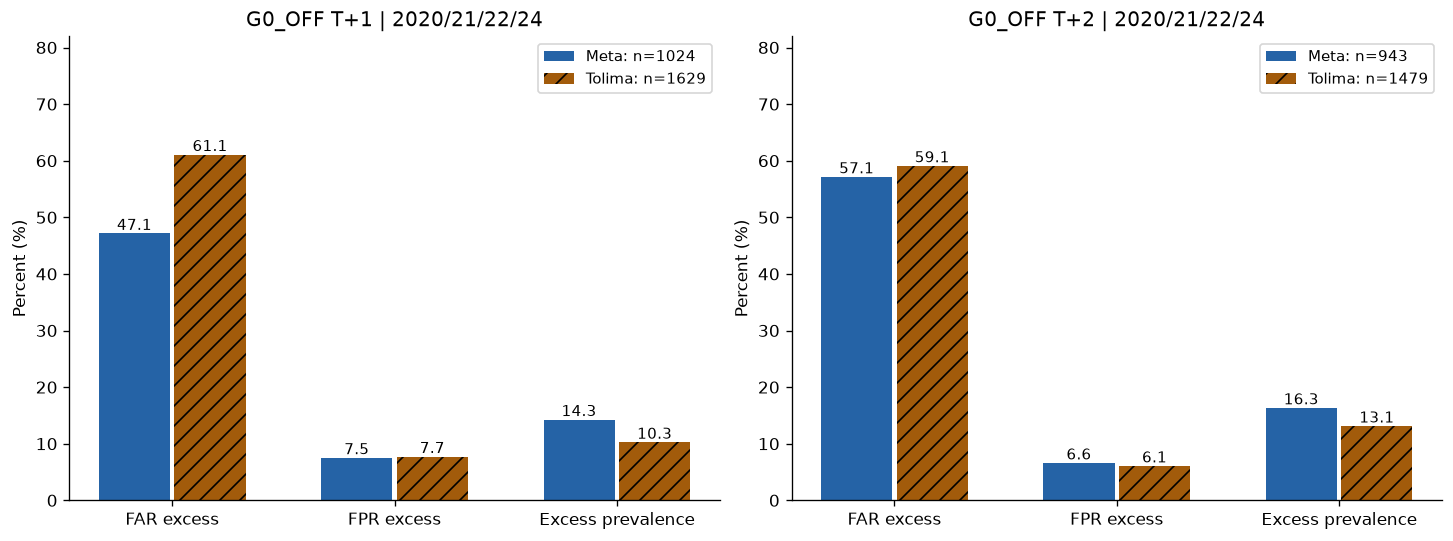

In [6]:
department = group_table(d, ["horizon", "arm", "department_code"])
annual_department = group_table(d, ["horizon", "year", "arm", "department_code"])


def far_identity(prevalence, sensitivity, fpr):
    return ratio(fpr * (1 - prevalence), sensitivity * prevalence + fpr * (1 - prevalence))


decomposition = []
for (h, arm), frame in department.groupby(["horizon", "arm"]):
    if arm == "PERSISTENCE":
        continue
    indexed = frame.set_index("department_code")
    a, b = indexed.loc["50"], indexed.loc["73"]
    factors = ["excess_prevalence", "excess_sensitivity", "fpr"]
    for row in [a, b]:
        assert np.isclose(far_identity(*[row[k] for k in factors]), row.far)
    contributions = dict.fromkeys(factors, 0.0)
    for order in itertools.permutations(factors):
        current = {k: a[k] for k in factors}
        for factor in order:
            before = far_identity(*[current[k] for k in factors])
            current[factor] = b[factor]
            contributions[factor] += (far_identity(*[current[k] for k in factors]) - before) / 6
    prevalence = g0[g0.horizon.eq(h)].target_excess.mean()
    standardized_a = far_identity(prevalence, a.excess_sensitivity, a.fpr)
    standardized_b = far_identity(prevalence, b.excess_sensitivity, b.fpr)
    gap = b.far - a.far
    assert np.isclose(sum(contributions.values()), gap)
    decomposition.append(
        dict(
            horizon=h,
            arm=arm,
            observed_gap_pp=100 * gap,
            prevalence_pp=100 * contributions["excess_prevalence"],
            sensitivity_pp=100 * contributions["excess_sensitivity"],
            fpr_pp=100 * contributions["fpr"],
            reference_prevalence=prevalence,
            standardized_Meta_far=standardized_a,
            standardized_Tolima_far=standardized_b,
            standardized_gap_pp=100 * (standardized_b - standardized_a),
        )
    )
decomposition = pd.DataFrame(decomposition)
tables.update(
    department=department, annual_department=annual_department, decomposition=decomposition
)
display(department[department.arm.eq("G0_OFF")].round(4))
display(decomposition[decomposition.arm.eq("G0_OFF")].round(4))


def finish(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    display(Image(data=(FIGURES / f"{name}.png").read_bytes()))
    plt.close(fig)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
for h, ax in zip([1, 2], axes, strict=True):
    part = department[(department.arm == "G0_OFF") & (department.horizon == h)].set_index(
        "department_code"
    )
    for i, (dep, label) in enumerate([("50", "Meta"), ("73", "Tolima")]):
        row = part.loc[dep]
        values = 100 * row[["far", "fpr", "excess_prevalence"]].to_numpy(float)
        bars = ax.bar(
            np.arange(3) + i * 0.34,
            values,
            width=0.32,
            label=f"{label}: n={int(row.rows)}",
            color=COLORS[label],
            hatch=["", "//"][i],
        )
        ax.bar_label(bars, fmt="%.1f", fontsize=9)
    ax.set(
        xticks=np.arange(3) + 0.17,
        xticklabels=["FAR excess", "FPR excess", "Excess prevalence"],
        ylabel="Percent (%)",
        ylim=(0, 82),
        title=f"G0_OFF T+{h} | 2020/21/22/24",
    )
    ax.legend(fontsize=9)
finish(fig, "01_department_rates")

At T+1, G0_OFF FPRs are 7.52%/7.73% in Meta/Tolima, but FARs are 47.14%/61.08%. The 13.94 pp gap decomposes into prevalence +9.28, excess sensitivity +3.98 and FPR +0.68 pp. At common prevalence the gap is +4.69 pp. At T+2, the observed +1.95 pp gap reverses to −4.28 pp at common excess prevalence; onset and excess targets must remain separate.

## 3. Probability separability

AP and AUROC concern **onset**, whereas FAR concerns excess. AP depends on
prevalence; `AP/prevalence` is descriptive context, not a corrected causal ranking.
Each panel below is one annual G0_OFF procedure. Histograms show fractions within
TP/FP/FN/TN onset classes, with their denominators; annual probability scales are
never pooled for ranking or score-distribution interpretation. Only the saved
threshold is drawn. Quantiles and signed distances to that threshold are retained
for every model/year/horizon/outcome in the private publication.

,horizon,year,arm,rows,onsets,prevalence,AP,...,mean_score,calibration_gap,AP_over_prevalence,threshold,score_q25,score_median,score_q75
0,1,2020,G0_OFF,661,69,0.1044,0.3423,...,0.1104,0.0060,3.2789,0.1852,0.0599,0.0923,0.1356
4,1,2021,G0_OFF,846,52,0.0615,0.1995,...,0.1071,0.0457,3.2452,0.2504,0.0523,0.0992,0.1300
8,1,2022,G0_OFF,693,89,0.1284,0.4546,...,0.2404,0.1119,3.5398,0.3574,0.1540,0.2276,0.2989
12,1,2024,G0_OFF,453,103,0.2274,0.5251,...,0.1048,-0.1226,2.3095,0.1500,0.0613,0.0835,0.1281
16,2,2020,G0_OFF,588,51,0.0867,0.2770,...,0.0724,-0.0143,3.1938,0.1146,0.0478,0.0643,0.0903
20,2,2021,G0_OFF,779,45,0.0578,0.2265,...,0.0872,0.0294,3.9202,0.2008,0.0500,0.0807,0.1097
24,2,2022,G0_OFF,641,62,0.0967,0.2110,...,0.1748,0.0781,2.1814,0.2620,0.1158,0.1713,0.2164
28,2,2024,G0_OFF,414,61,0.1473,0.3607,...,0.0721,-0.0753,2.4481,0.1060,0.0473,0.0635,0.0832


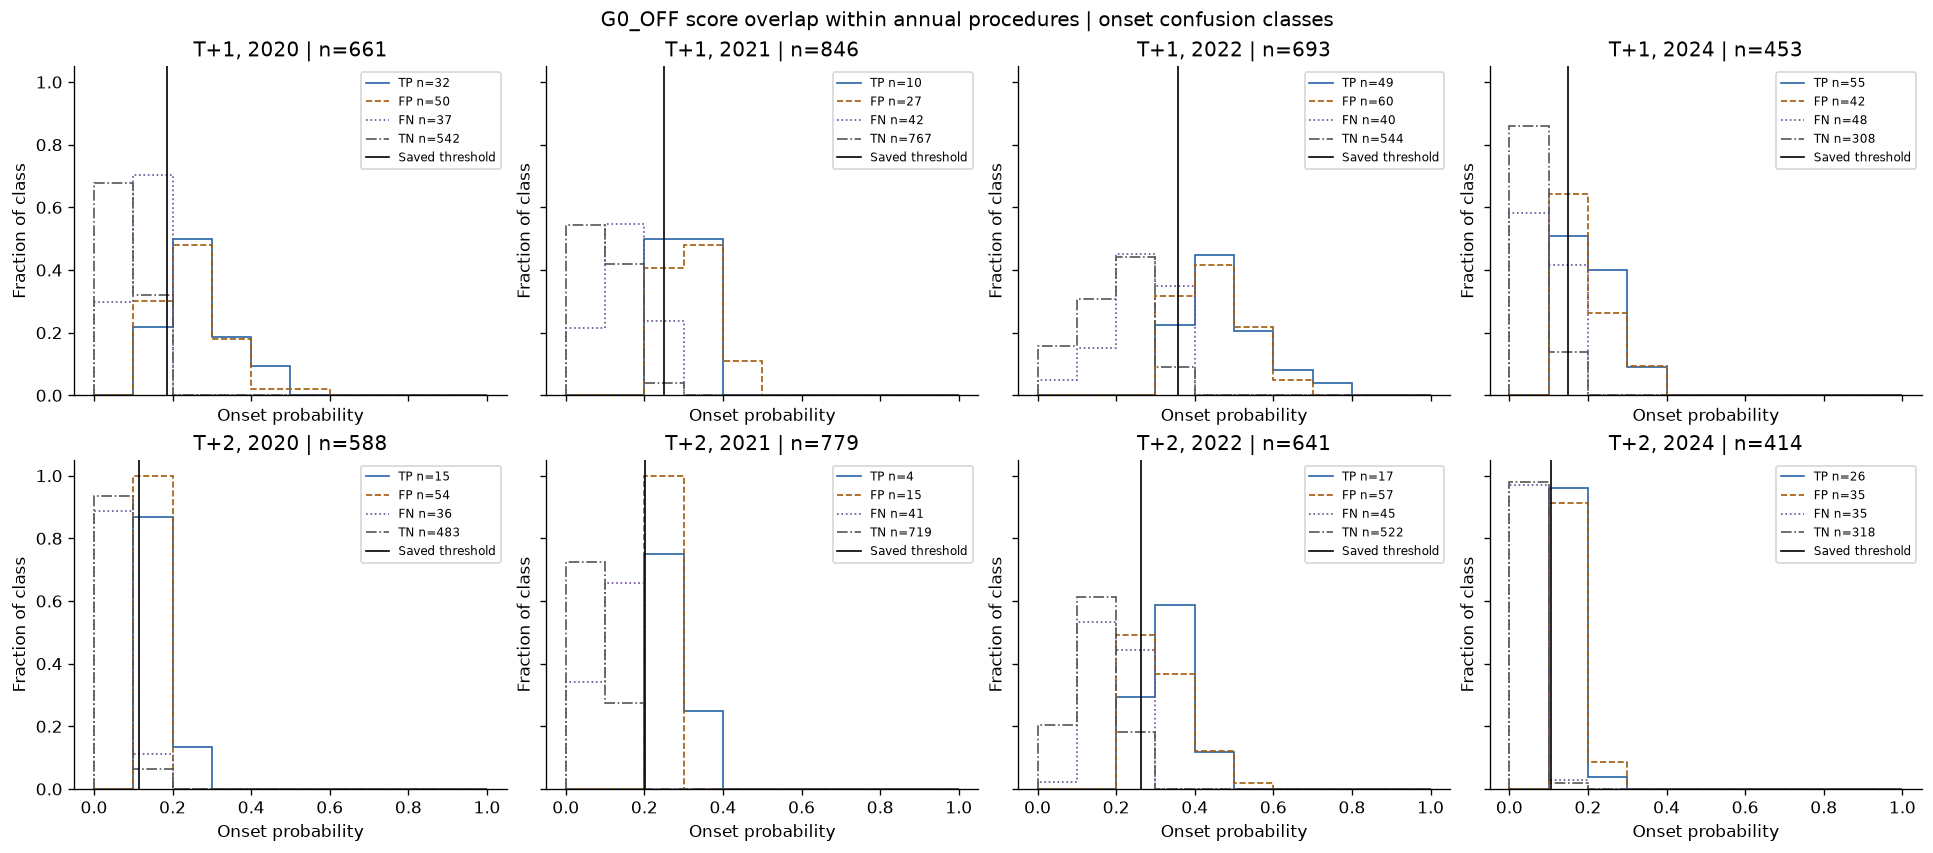

In [7]:
discrimination = []
quantiles = []
real_class = []
score_ecdf = []
reliability = []
for (h, year, arm), part in d[d.arm.isin(MODELS)].groupby(["horizon", "year", "arm"]):
    assert part.model_identity.nunique() == 1 and part.threshold.nunique() == 1
    prevalence = part.truth.mean()
    discrimination.append(
        dict(
            horizon=h,
            year=year,
            arm=arm,
            rows=len(part),
            onsets=int(part.truth.sum()),
            prevalence=prevalence,
            AP=average_precision_score(part.truth, part.score),
            AUROC=roc_auc_score(part.truth, part.score),
            brier=brier_score_loss(part.truth, part.score),
            mean_score=part.score.mean(),
            calibration_gap=part.score.mean() - prevalence,
            AP_over_prevalence=average_precision_score(part.truth, part.score) / prevalence,
            threshold=part.threshold.iloc[0],
            score_q25=part.score.quantile(0.25),
            score_median=part.score.median(),
            score_q75=part.score.quantile(0.75),
        )
    )
    for truth, sub in part.groupby("truth"):
        real_class.append(
            dict(
                horizon=h,
                year=year,
                arm=arm,
                truth=truth,
                rows=len(sub),
                q10=sub.score.quantile(0.1),
                q25=sub.score.quantile(0.25),
                median=sub.score.median(),
                q75=sub.score.quantile(0.75),
                q90=sub.score.quantile(0.9),
            )
        )
        for point in np.linspace(0, 1, 11):
            score_ecdf.append(
                dict(
                    horizon=h,
                    year=year,
                    arm=arm,
                    truth=truth,
                    score_point=point,
                    rows=len(sub),
                    ecdf=sub.score.le(point).mean(),
                )
            )
    for outcome, sub in part.groupby("onset_class"):
        margins = sub.score - sub.threshold
        quantiles.append(
            dict(
                horizon=h,
                year=year,
                arm=arm,
                outcome=outcome,
                rows=len(sub),
                score_q10=sub.score.quantile(0.1),
                score_median=sub.score.median(),
                score_q90=sub.score.quantile(0.9),
                margin_q10=margins.quantile(0.1),
                margin_median=margins.median(),
                margin_q90=margins.quantile(0.9),
                within_005=int(margins.abs().le(0.05).sum()),
                above_005_to_015=int((margins.gt(0.05) & margins.le(0.15)).sum()),
                above_015=int(margins.gt(0.15).sum()),
            )
        )
    bins = pd.cut(part.score, np.linspace(0, 1, 11), include_lowest=True)
    for band, sub in part.groupby(bins, observed=True):
        events = int(sub.truth.sum())
        reliability.append(
            dict(
                horizon=h,
                year=year,
                arm=arm,
                bin=str(band),
                rows=len(sub),
                onsets=events,
                mean_score=sub.score.mean(),
                observed=sub.truth.mean(),
                supported=len(sub) >= 30 and events >= 5 and len(sub) - events >= 5,
            )
        )
discrimination = pd.DataFrame(discrimination)
tables.update(
    discrimination=discrimination,
    score_quantiles=pd.DataFrame(quantiles),
    real_class_quantiles=pd.DataFrame(real_class),
    score_ecdf=pd.DataFrame(score_ecdf),
    reliability=pd.DataFrame(reliability),
)
display(discrimination[discrimination.arm.eq("G0_OFF")].round(4))

fig, axes = plt.subplots(2, 4, figsize=(16, 7), layout="constrained", sharex=True, sharey=True)
styles = {
    "TP": ("#2563a6", "-"),
    "FP": ("#a25b0b", "--"),
    "FN": ("#6b4c9a", ":"),
    "TN": ("#555555", "-."),
}
for h, row_axes in zip([1, 2], axes, strict=True):
    for year, ax in zip(YEARS, row_axes, strict=True):
        part = g0[(g0.horizon == h) & (g0.year == year)]
        for outcome, (color, style) in styles.items():
            sub = part[part.onset_class.eq(outcome)]
            values, edges = np.histogram(sub.score, bins=np.linspace(0, 1, 11))
            if len(sub):
                ax.stairs(
                    values / len(sub),
                    edges,
                    label=f"{outcome} n={len(sub)}",
                    color=color,
                    linestyle=style,
                )
        ax.axvline(part.threshold.iloc[0], color="black", linewidth=1, label="Saved threshold")
        ax.set(
            title=f"T+{h}, {year} | n={len(part)}",
            xlabel="Onset probability",
            ylabel="Fraction of class",
        )
        ax.legend(fontsize=7)
fig.suptitle("G0_OFF score overlap within annual procedures | onset confusion classes")
finish(fig, "02_probability_distributions")

True and false alerts occupy overlapping score bins in every annual procedure. G0_OFF AUROC exceeds 0.5 in all eight cells, yet T+2/2022 reaches only 0.713 (AP 0.211 versus onset prevalence 0.0967). This supports limited separability, without establishing that discrimination alone causes failure of the academic rule. The other models and real-class quantiles/ECDFs remain in the derived tables.

### Paired errors and detections

All four model decisions share identical municipality-origin keys within a horizon.
We count each opportunity once for the multiplicity table. Shared errors are not
independent replications; exclusive errors are defined against the other three models.
CHANNEL comparisons use the same observations; successful G0-only detections are
retained alongside its extra false alerts.

In [8]:
multiplicity = []
exclusive = []
overlap = []
for (h, year), part in d.groupby(["horizon", "year"]):
    matrix = part.pivot(index=KEYS, columns="arm", values="alert")
    labels = part[part.arm.eq("CHANNEL")].set_index(KEYS).reindex(matrix.index)
    votes = matrix[MODELS].sum(axis=1)
    for outcome, mask in [
        ("non_excess", labels.target_excess.eq(0)),
        ("onset", labels.truth.eq(1)),
    ]:
        for k in range(5):
            multiplicity.append(
                dict(
                    horizon=h,
                    year=year,
                    outcome=outcome,
                    models_alerting=k,
                    rows=int((mask & votes.eq(k)).sum()),
                    opportunities=int(mask.sum()),
                )
            )
    for arm in MODELS:
        only = matrix[arm] & matrix[[a for a in MODELS if a != arm]].sum(axis=1).eq(0)
        exclusive.append(
            dict(
                horizon=h,
                year=year,
                arm=arm,
                exclusive_false_excess=int((only & labels.target_excess.eq(0)).sum()),
                exclusive_detected=int((only & labels.truth.eq(1)).sum()),
            )
        )
    for a, b in itertools.combinations([*MODELS, "CHANNEL"], 2):
        for outcome, mask in [
            ("false_excess", labels.target_excess.eq(0)),
            ("detected", labels.truth.eq(1)),
        ]:
            overlap.append(
                dict(
                    horizon=h,
                    year=year,
                    a=a,
                    b=b,
                    outcome=outcome,
                    both=int((mask & matrix[a] & matrix[b]).sum()),
                    a_only=int((mask & matrix[a] & ~matrix[b]).sum()),
                    b_only=int((mask & ~matrix[a] & matrix[b]).sum()),
                    neither=int((mask & ~matrix[a] & ~matrix[b]).sum()),
                )
            )
tables.update(
    multiplicity=pd.DataFrame(multiplicity),
    exclusive=pd.DataFrame(exclusive),
    overlap=pd.DataFrame(overlap),
)
diagnostic = json.loads((ROOT / DIAG / "tables.json").read_text())
expected_shared = pd.DataFrame(diagnostic["shared_errors"])
expected_shared = expected_shared[expected_shared.outcome.isin(["non_excess", "onset"])].rename(
    columns={"number_models_alerting": "models_alerting"}
)
cols = ["horizon", "year", "outcome", "models_alerting", "rows", "opportunities"]
order = cols[:4]
pd.testing.assert_frame_equal(
    tables["multiplicity"][cols].sort_values(order).reset_index(drop=True),
    expected_shared[cols].sort_values(order).reset_index(drop=True),
)
display(
    tables["overlap"]
    .query("a == 'G0_OFF' and b == 'CHANNEL'")
    .groupby(["horizon", "outcome"])[["both", "a_only", "b_only", "neither"]]
    .sum()
)

both  a_only  b_only  neither
horizon outcome                                    
1       detected        75      71      19      148
        false_excess    61     118      24     2137
2       detected        29      33      17      140
        false_excess    38      92      76     1868

## 4. Calibration and temporal stability

Mean predicted minus observed onset frequency measures calibration in the large.
Brier combines calibration and discrimination; it does not isolate either component.
Reliability uses fixed bins and the support rule in Chapter 1; unsupported bins
remain in the private table but no reliable curve is claimed there. Annual
procedures were separately trained/calibrated: changes mix composition and procedure
changes, and cannot be attributed to drift of a single fixed model.

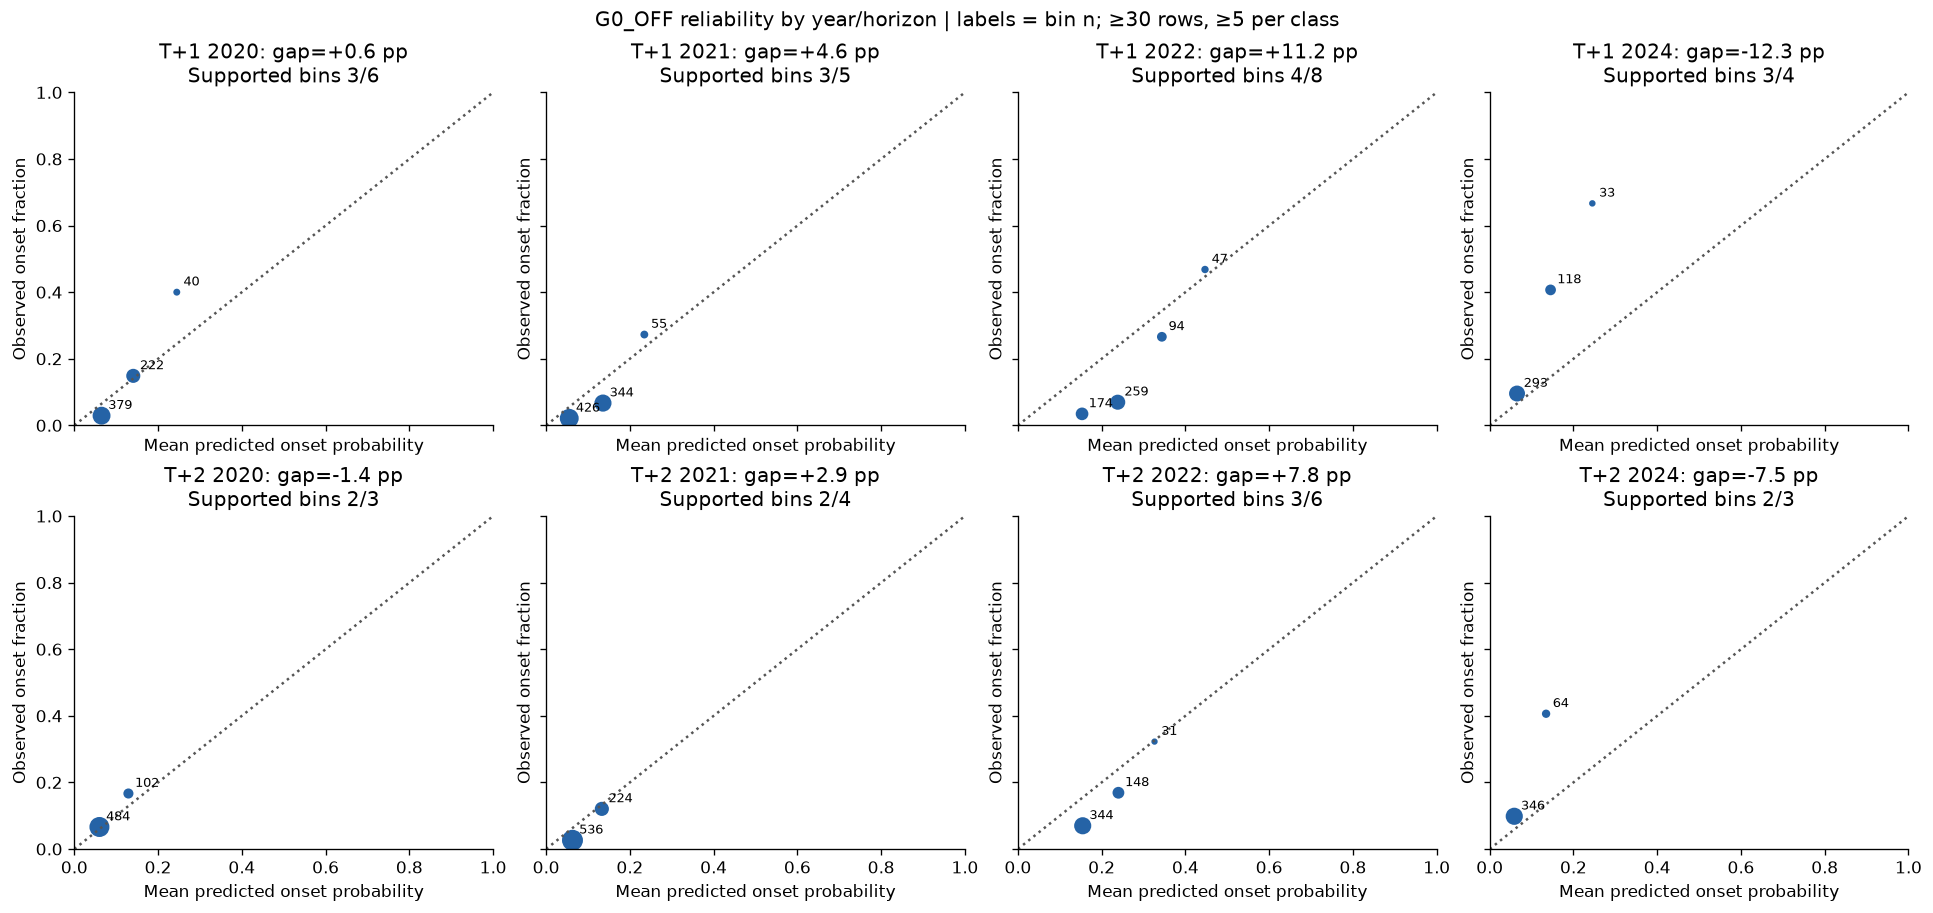

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5), layout="constrained", sharex=True, sharey=True)
for h, row_axes in zip([1, 2], axes, strict=True):
    for year, ax in zip(YEARS, row_axes, strict=True):
        rel = tables["reliability"].query("arm == 'G0_OFF' and horizon == @h and year == @year")
        supported = rel[rel.supported]
        ax.plot([0, 1], [0, 1], ":", color="#555555")
        ax.scatter(
            supported.mean_score,
            supported.observed,
            s=supported.rows / 4,
            color="#2563a6",
            marker="o",
        )
        for row in supported.itertuples():
            ax.annotate(
                str(row.rows),
                (row.mean_score, row.observed),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=8,
            )
        metric = discrimination.query("arm == 'G0_OFF' and horizon == @h and year == @year").iloc[0]
        ax.set(
            title=(
                f"T+{h} {year}: gap={100 * metric.calibration_gap:+.1f} pp\n"
                f"Supported bins {len(supported)}/{len(rel)}"
            ),
            xlabel="Mean predicted onset probability",
            ylabel="Observed onset fraction",
            xlim=(0, 1),
            ylim=(0, 1),
        )
fig.suptitle("G0_OFF reliability by year/horizon | labels = bin n; ≥30 rows, ≥5 per class")
finish(fig, "03_reliability")

G0_OFF calibration-in-the-large gaps are +11.19/+7.81 pp in 2022 and −12.26/−7.53 pp in 2024 (T+1/T+2). T+1/2022 AUROC is 0.830, above the other years, despite all four models failing the annual academic FAR margin. Ranking, prevalence, calibration and a relative decision constraint describe different properties.

### DELTA selection versus evaluation, without new policy selection

Read the already published policies/frontier and recovered selection probabilities.
The following calculations describe probability quality in the historical selection
block and its corresponding evaluation block. They do not compare identical observations
across time or authenticate absent original selection arrays. Evaluation copies are
paired exactly with benchmark G0_OFF. Missing P1 policies stay unavailable in every
complete-horizon comparison. No candidate thresholds are recalculated.

,horizon,year,stage,rows,onsets,prevalence,mean_score,calibration_gap,AP,AUROC,brier
0,1,2020,selection,376,118,0.3138,0.1356,-0.1782,0.5133,0.7138,0.2292
1,1,2020,evaluation,661,69,0.1044,0.1104,0.0060,0.3423,0.8126,0.0823
2,1,2021,selection,661,69,0.1044,0.1425,0.0381,0.3400,0.8147,0.0822
3,1,2021,evaluation,846,52,0.0615,0.1071,0.0457,0.1995,0.7754,0.0558
4,1,2022,selection,846,52,0.0615,0.2052,0.1437,0.1862,0.7630,0.0778
5,1,2022,evaluation,693,89,0.1284,0.2404,0.1119,0.4546,0.8301,0.1038
6,1,2024,selection,410,125,0.3049,0.1050,-0.1998,0.5278,0.7401,0.2349
7,1,2024,evaluation,453,103,0.2274,0.1048,-0.1226,0.5251,0.7996,0.1695
8,2,2020,selection,355,73,0.2056,0.0787,-0.1269,0.3344,0.6325,0.1743
9,2,2020,evaluation,588,51,0.0867,0.0724,-0.0143,0.2770,0.7562,0.0750


,horizon,year,status,threshold,development_channel_far,development_P1_far,evaluation_P1_far,evaluation_channel_far,evaluation_condition_C
0,1,2020,EVALUABLE,0.2586,0.3333,0.3611,0.6061,0.5814,True
1,1,2021,EVALUABLE,0.2746,0.5814,0.6167,0.7037,0.5455,False
2,1,2022,NO_EVALUABLE,NaN,0.5455,NaN,NaN,0.4419,NaN
3,1,2024,EVALUABLE,0.2034,0.3519,0.4000,0.3415,0.4085,True
4,2,2020,EVALUABLE,0.1146,0.3448,0.3333,0.7101,0.6364,False
5,2,2021,EVALUABLE,0.1448,0.6364,0.6855,0.7407,0.7308,True
6,2,2022,EVALUABLE,0.2473,0.7308,0.7767,0.6277,0.5000,False
7,2,2024,NO_EVALUABLE,NaN,0.2549,NaN,NaN,0.4699,NaN


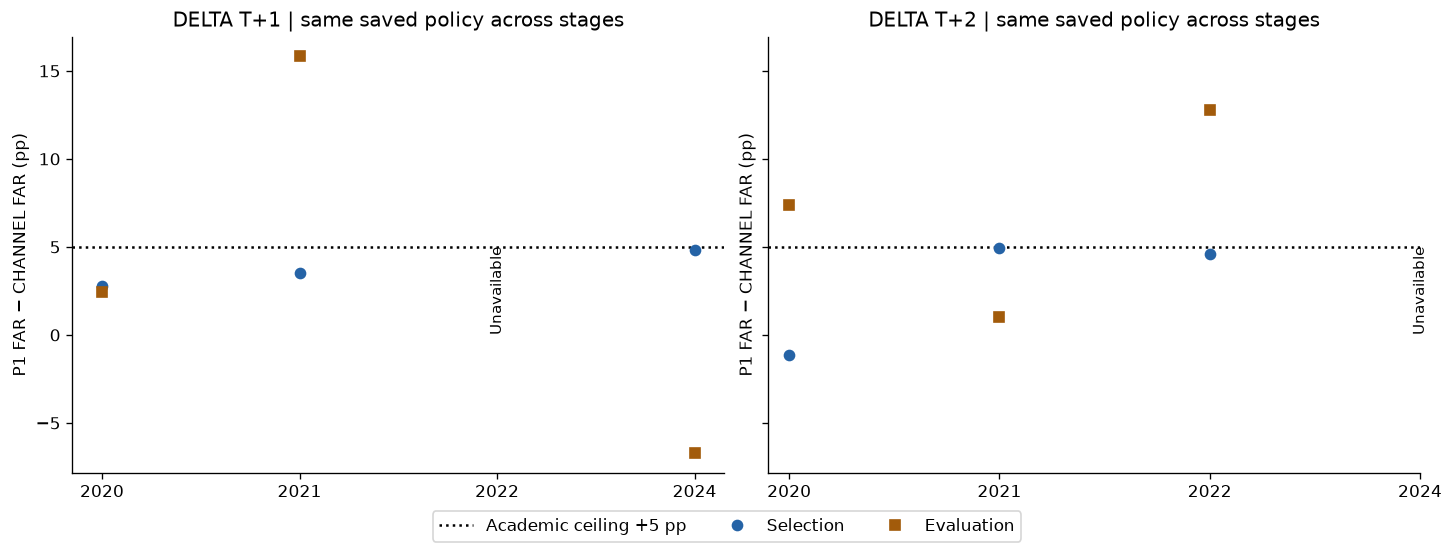

In [10]:
transport = pd.read_csv(ROOT / DELTA / "transport.csv")
frontier = pd.read_csv(ROOT / DELTA / "selection_frontier.csv")
delta_metrics = pd.read_csv(ROOT / DELTA / "metrics.csv", dtype={"year": str, "department": str})
selection_comparison = []
feasibility = []
for h in [1, 2]:
    for year in YEARS:
        selection = read_csv(RECOVERY + f"/selection-h{h}-{year}.csv")
        evaluation = g0[(g0.horizon == h) & (g0.year == year)]
        assert selection.role.eq("selection").all()
        assert set(selection.target_month.str[:4].astype(int)) == {year - 1}
        assert selection.target_month.max() < evaluation.target_month.min()
        for stage, part, truth in [
            ("selection", selection, selection.onset_target),
            ("evaluation", evaluation, evaluation.truth),
        ]:
            selection_comparison.append(
                dict(
                    horizon=h,
                    year=year,
                    stage=stage,
                    rows=len(part),
                    onsets=int(truth.sum()),
                    prevalence=truth.mean(),
                    mean_score=part.score.mean(),
                    calibration_gap=part.score.mean() - truth.mean(),
                    AP=average_precision_score(truth, part.score),
                    AUROC=roc_auc_score(truth, part.score),
                    brier=brier_score_loss(truth, part.score),
                )
            )
        saved = frontier[(frontier.horizon == h) & (frontier.year == year)]
        feasibility.append(
            dict(
                horizon=h,
                year=year,
                saved_thresholds=int(saved.threshold.notna().sum()),
                saved_feasible=int(saved.feasible.sum()),
            )
        )
# Independently reconcile every DELTA metric stratum and retain null decisions.
for row in delta_metrics.itertuples(index=False):
    part = delta[(delta.horizon == row.horizon) & (delta.arm == row.arm)]
    if row.year != "all":
        part = part[part.year.eq(int(row.year))]
    if row.department != "all":
        part = part[part.department_code.eq(row.department)]
    assert len(part) == row.rows and part.truth.sum() == row.onsets
    assert np.isclose(average_precision_score(part.truth, part.score), row.average_precision)
    assert np.isclose(brier_score_loss(part.truth, part.score), row.brier)
    if not part.available.all():
        assert row.academic_status == "NO_EVALUABLE" and pd.isna(row.alerts)
        continue
    actual = describe(part)
    for ours, theirs in [
        ("detected", "detected"),
        ("alerts", "alerts"),
        ("false_excess", "false_alerts_excess"),
        ("false_onset", "false_alerts_onset"),
        ("far", "far_excess"),
        ("sensitivity", "sensitivity"),
    ]:
        assert np.isclose(actual[ours], getattr(row, theirs), equal_nan=True)
tables.update(
    selection_comparison=pd.DataFrame(selection_comparison),
    feasibility=pd.DataFrame(feasibility),
    transport=transport,
)
display(tables["selection_comparison"].round(4))
display(transport.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained", sharey=True)
for h, ax in zip([1, 2], axes, strict=True):
    part = transport[transport.horizon.eq(h)].set_index("year").reindex(YEARS)
    ax.axhline(5, linestyle=":", color="black", label="Academic ceiling +5 pp")
    for stage, model, channel, marker, color in [
        ("Selection", "development_P1_far", "development_channel_far", "o", "#2563a6"),
        ("Evaluation", "evaluation_P1_far", "evaluation_channel_far", "s", "#a25b0b"),
    ]:
        ax.plot(
            np.arange(4),
            100 * (part[model] - part[channel]),
            marker=marker,
            color=color,
            linestyle="none",
            label=stage,
        )
    for i, row in enumerate(part.itertuples()):
        if row.status != "EVALUABLE":
            ax.text(i, 0, "Unavailable", rotation=90, ha="center", va="bottom", fontsize=9)
    ax.set(
        xticks=range(4),
        xticklabels=YEARS,
        ylabel="P1 FAR − CHANNEL FAR (pp)",
        title=f"DELTA T+{h} | same saved policy across stages",
    )
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=3)
finish(fig, "04_delta_margin_transport")

All six available P1 policies met their selection constraint; three retain C in evaluation. The T+1/2022 and T+2/2024 policies are unavailable because the published frontier has zero feasible thresholds. No partial-year aggregate substitutes for a complete P1 comparison. These are already consumed results, not an additional experiment.

## 5. Territorial heterogeneity and statistical support

Municipal rates retain every eligible month; exposure is rows/12, never four
complete years by assumption. No evaluation-based transmission clusters are created.
BETA's admitted contract has **no temporally validated transmission profile**;
profile-specific conclusions are therefore blocked, not replaced by departments.
Departments remain descriptive geographic controls. Wilson intervals already expose
the small-denominator problem; Jeffreys intervals add no necessary decision evidence.
Municipal rankings are not durable risk categories or recommendations to exclude towns.

,0,1
horizon,1.0000,2.0000
municipalities,76.0000,76.0000
municipality_years,300.0000,298.0000
pooled_under5_onsets,43.0000,64.0000
annual_zero_onsets,105.0000,129.0000
annual_under3_onsets,273.0000,294.0000
annual_under5_alerts,295.0000,297.0000
annual_zero_alerts,142.0000,162.0000
median_annual_sensitivity_width,0.7935,0.7935
median_annual_far_width,0.7935,0.7935


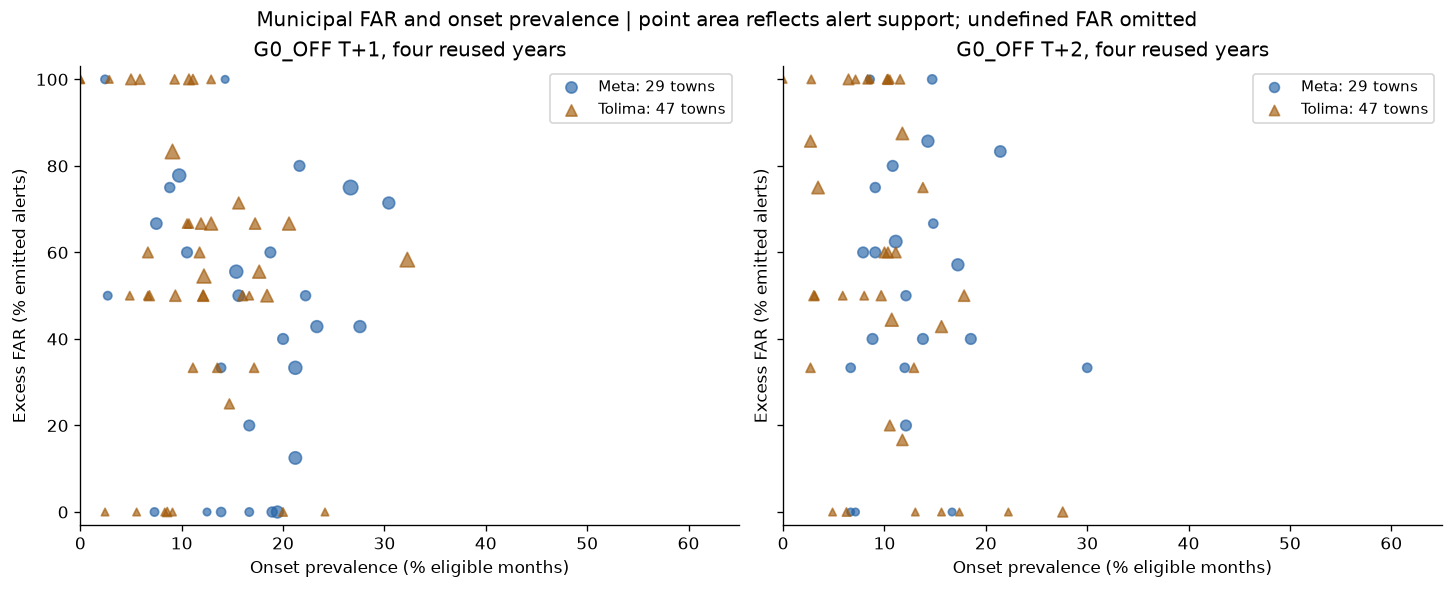

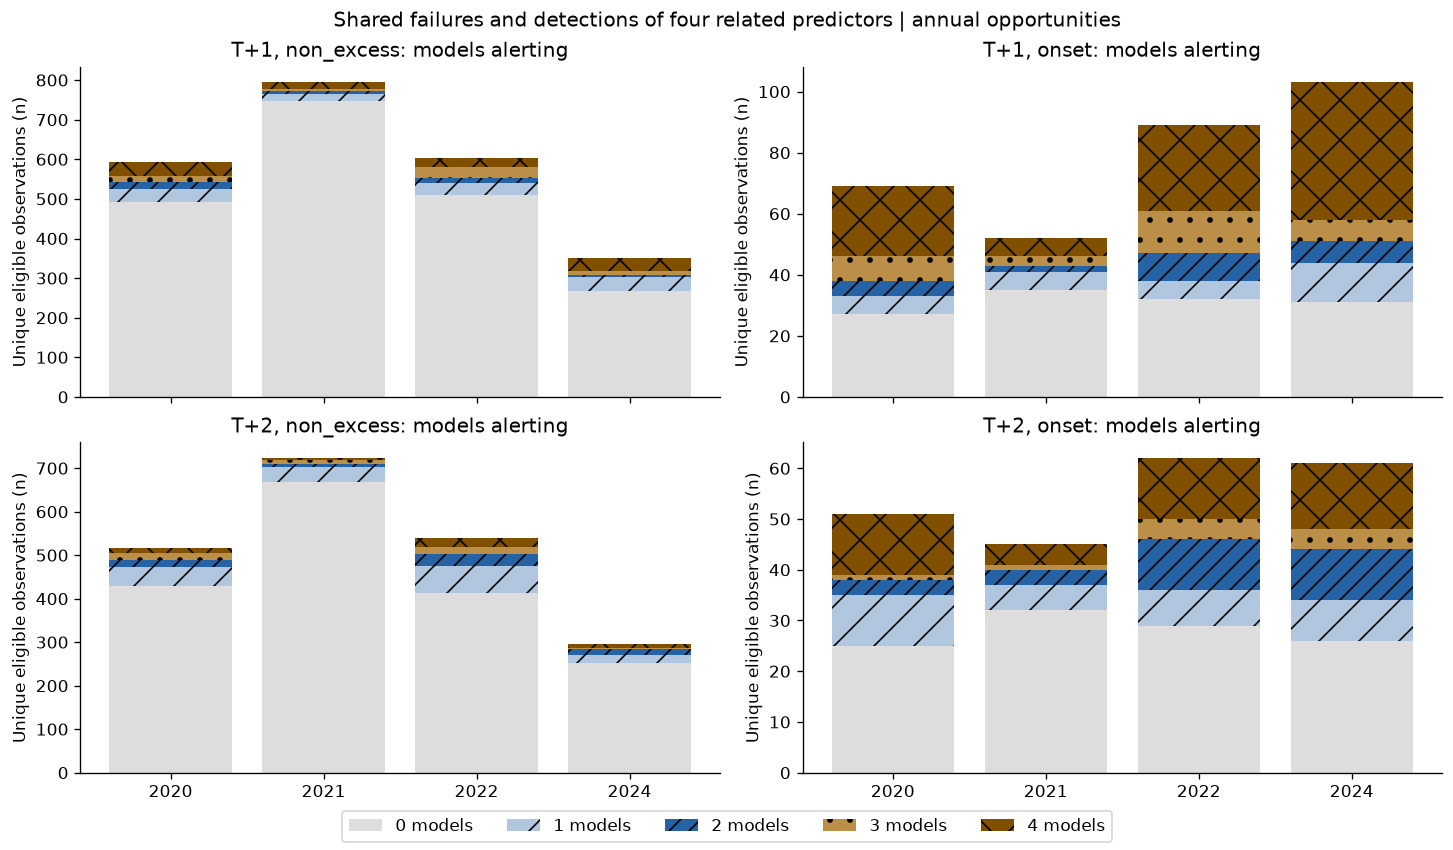

In [11]:
def wilson(k, n):
    if n == 0:
        return np.nan, np.nan
    z = 1.959963984540054
    center = (k / n + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt((k / n) * (1 - k / n) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0, center - half), min(1, center + half)


municipal = group_table(d, ["horizon", "arm", "municipality_code", "department_code"])
municipal_year = group_table(d, ["horizon", "year", "arm", "municipality_code", "department_code"])
for frame in [municipal, municipal_year]:
    for metric, numerator, denominator in [
        ("sensitivity", "detected", "onsets"),
        ("far", "false_excess", "alerts"),
    ]:
        bounds = [
            wilson(int(k), int(n))
            for k, n in zip(frame[numerator], frame[denominator], strict=True)
        ]
        frame[[metric + "_lo", metric + "_hi"]] = bounds
        frame[metric + "_width"] = frame[metric + "_hi"] - frame[metric + "_lo"]
support = []
for h in [1, 2]:
    pooled = municipal[(municipal.horizon == h) & (municipal.arm == "G0_OFF")]
    yearly = municipal_year[(municipal_year.horizon == h) & (municipal_year.arm == "G0_OFF")]
    ordered = pooled.sort_values("false_excess", ascending=False)
    support.append(
        dict(
            horizon=h,
            municipalities=len(pooled),
            municipality_years=len(yearly),
            pooled_under5_onsets=int(pooled.onsets.lt(5).sum()),
            annual_zero_onsets=int(yearly.onsets.eq(0).sum()),
            annual_under3_onsets=int(yearly.onsets.lt(3).sum()),
            annual_under5_alerts=int(yearly.alerts.lt(5).sum()),
            annual_zero_alerts=int(yearly.alerts.eq(0).sum()),
            median_annual_sensitivity_width=yearly.sensitivity_width.median(),
            median_annual_far_width=yearly.far_width.median(),
            municipalities_with_FP=int(pooled.false_excess.gt(0).sum()),
            top7_FP=int(ordered.head(7).false_excess.sum()),
            total_FP=int(pooled.false_excess.sum()),
            top7_exposure=ordered.head(7).exposure.sum(),
            total_exposure=pooled.exposure.sum(),
            annual_onsets_q25=yearly.onsets.quantile(0.25),
            annual_onsets_median=yearly.onsets.median(),
            annual_onsets_q75=yearly.onsets.quantile(0.75),
        )
    )
support = pd.DataFrame(support)
tables.update(municipal=municipal, municipal_year=municipal_year, support=support)
display(support.T.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained", sharex=True, sharey=True)
for h, ax in zip([1, 2], axes, strict=True):
    for dep, label, marker in [("50", "Meta", "o"), ("73", "Tolima", "^")]:
        part = municipal[
            (municipal.horizon == h)
            & (municipal.arm == "G0_OFF")
            & (municipal.department_code == dep)
        ]
        ax.scatter(
            100 * part.onset_prevalence,
            100 * part.far,
            s=15 + part.alerts * 5,
            color=COLORS[label],
            marker=marker,
            alpha=0.65,
            label=f"{label}: {len(part)} towns",
        )
    ax.set(
        title=f"G0_OFF T+{h}, four reused years",
        xlabel="Onset prevalence (% eligible months)",
        ylabel="Excess FAR (% emitted alerts)",
        xlim=(0, 65),
        ylim=(-3, 103),
    )
    ax.legend(fontsize=9)
fig.suptitle(
    "Municipal FAR and onset prevalence | point area reflects alert support; undefined FAR omitted"
)
finish(fig, "05_municipal_rates")

fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained", sharex=True)
for i, h in enumerate([1, 2]):
    for j, outcome in enumerate(["non_excess", "onset"]):
        ax = axes[i, j]
        part = tables["multiplicity"].query("horizon == @h and outcome == @outcome")
        bottom = np.zeros(4)
        palette = ["#dddddd", "#b0c7df", "#2563a6", "#bc8f49", "#805000"]
        for k in range(5):
            counts = (
                part[part.models_alerting.eq(k)].set_index("year").reindex(YEARS).rows.to_numpy()
            )
            ax.bar(
                range(4),
                counts,
                bottom=bottom,
                label=f"{k} models",
                color=palette[k],
                hatch=["", "/", "//", ".", "x"][k],
            )
            bottom += counts
        ax.set(
            xticks=range(4),
            xticklabels=YEARS,
            ylabel="Unique eligible observations (n)",
            title=f"T+{h}, {outcome}: models alerting",
        )
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=5)
fig.suptitle("Shared failures and detections of four related predictors | annual opportunities")
finish(fig, "06_shared_outcomes")

At municipality-year resolution 105/300 T+1 and 129/298 T+2 cells have no onsets; 273/300 and 294/298 have fewer than three. Median Wilson sensitivity and FAR reference widths among defined cells are both 79.35 pp. Pooled four-year scatter points do not establish stable municipal policies; dependence further limits the intervals.

In 2022 all four models miss 32/89 T+1 and 29/62 T+2 onsets. Of 94/127 distinct non-excess observations falsely alerted by any model, 65/65 are shared by at least two. G0_OFF additionally detects 71/33 onsets missed by CHANNEL over all four years, but CHANNEL alone detects 19/17 missed by G0_OFF (T+1/T+2). Neither comparator uniformly contains the other.

## 6. Epidemiological boundary and synthesis

Known cases in T are compared with the **target-month** P75. Near-P75 means
absolute difference ≤1 case; ratios exclude P75=0, which is counted separately.
This is an explanatory descriptor of recorded outcomes, never a proposed filter.
Origin zones are known in T; target-minus-one excess below is consulted solely as
an outcome context, never an input or municipal profile.

EXP02's separate full-month cohort showed 87/912 onset labels changed under H5/H9
in 2024: 40 H5 onsets disappeared and 47 appeared. That is historical label-definition
sensitivity, not proof that any present error is a mislabeled outbreak. Its rates
must not be pooled with the eligible benchmark cohort or used to revise H5 here.

rows  near  equal  p75_zero
horizon group                                       
1       CHANNEL_only_FP    24    10      0         6
        G0_FN             167    84     44        38
        G0_FP             179   140     82        28
        G0_TN_excess     2161   702    383       332
        G0_TP             146    94     46        21
        G0_only_FP        118   107     82        20
        G0_only_TP         71    62     46        11
        both_FP            61    33      0         8
2       CHANNEL_only_FP    76    31      0         8
        G0_FN             157    81     46        30
        G0_FP             130    93     49        32
        G0_TN_excess     1944   677    364       297
        G0_TP              62    41     19        16
        G0_only_FP         92    74     49        24
        G0_only_TP         33    28     19        11
        both_FP            38    19      0         8

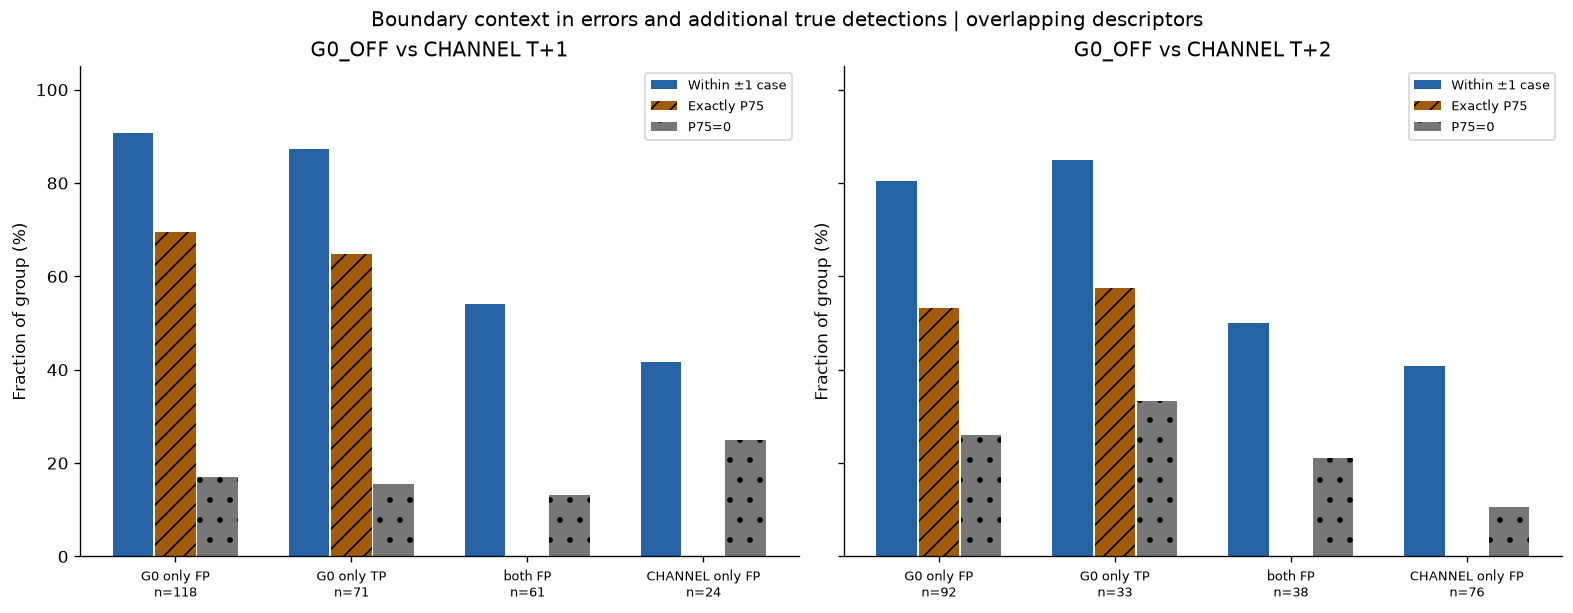

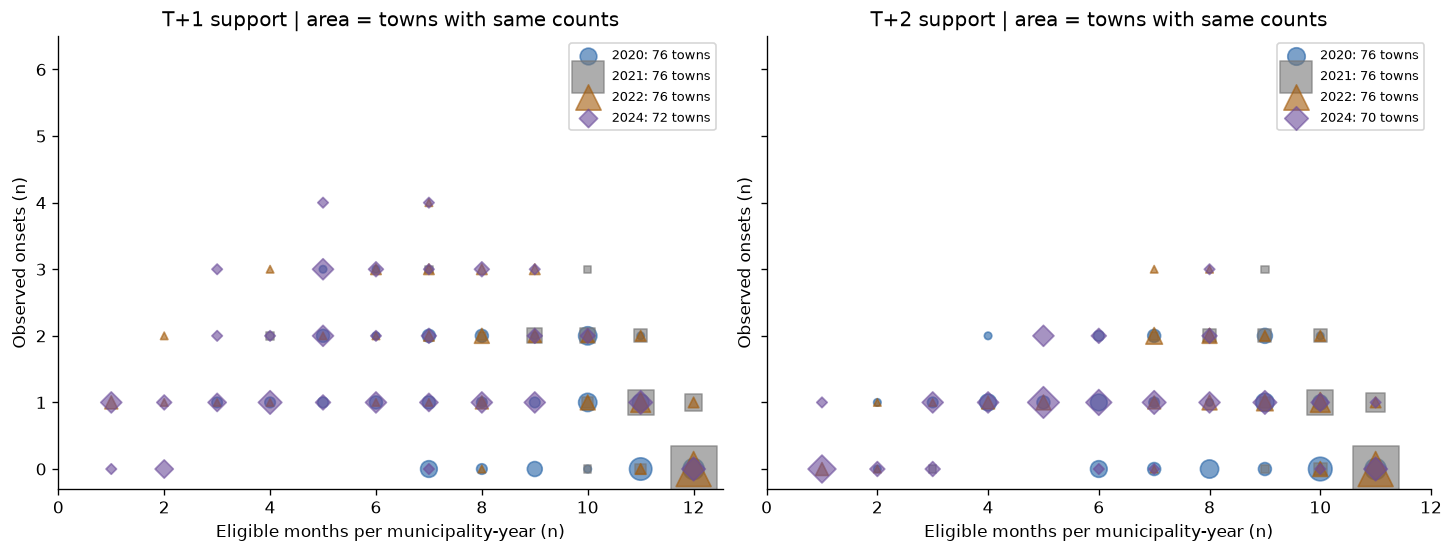

In [12]:
boundary_rows = []
zone_rows = []
for (h, year), part in g0.groupby(["horizon", "year"]):
    channel = d[(d.arm == "CHANNEL") & (d.horizon == h) & (d.year == year)].set_index(KEYS)
    part = part.set_index(KEYS).sort_index()
    channel = channel.reindex(part.index)
    groups = {
        "G0_only_FP": part.alert & ~channel.alert & part.target_excess.eq(0),
        "CHANNEL_only_FP": ~part.alert & channel.alert & part.target_excess.eq(0),
        "both_FP": part.alert & channel.alert & part.target_excess.eq(0),
        "G0_only_TP": part.alert & ~channel.alert & part.truth.eq(1),
        "G0_FP": part.alert & part.target_excess.eq(0),
        "G0_TP": part.alert & part.truth.eq(1),
        "G0_FN": ~part.alert & part.truth.eq(1),
        "G0_TN_excess": ~part.alert & part.target_excess.eq(0),
    }
    for group, mask in groups.items():
        sub = part[mask]
        near = (sub.origin_count - sub.target_p75).abs().le(1)
        valid_ratio = sub.origin_count.div(sub.target_p75.where(sub.target_p75.gt(0)))
        boundary_rows.append(
            dict(
                horizon=h,
                year=year,
                group=group,
                rows=len(sub),
                near=int(near.sum()),
                equal=int(sub.origin_count.eq(sub.target_p75).sum()),
                p75_zero=int(sub.target_p75.eq(0).sum()),
                cases_median=sub.origin_count.median(),
                p75_median=sub.target_p75.median(),
                ratio_median=valid_ratio.median(),
                ratio_n=int(valid_ratio.notna().sum()),
                margin_median=(sub.score - sub.threshold).median(),
            )
        )
        for zone, block in sub.groupby("origin_zone"):
            zone_rows.append(
                dict(horizon=h, year=year, group=group, origin_zone=zone, rows=len(block))
            )
boundary = pd.DataFrame(boundary_rows)
tables.update(boundary=boundary, origin_zones=pd.DataFrame(zone_rows))
for row in diagnostic["P1_groups"]:
    observed = boundary[(boundary.horizon == 1) & (boundary.group == row["group"])][
        ["rows", "near", "equal", "p75_zero"]
    ].sum()
    for ours, theirs in [
        ("rows", "rows"),
        ("near", "near_p75_one_case"),
        ("equal", "equal_p75"),
        ("p75_zero", "p75_zero"),
    ]:
        assert observed[ours] == row[theirs]
display(boundary.groupby(["horizon", "group"])[["rows", "near", "equal", "p75_zero"]].sum())

# The canonical table is needed only to resolve the prior state, not to rebuild labels.
canonical_spec = json.loads((ROOT / BENCH / "protocol.json").read_text())["sources"]["canonical"]
cm = verify_publication(canonical_spec["path"], canonical_spec["manifest_sha256"])
canonical = read_csv(canonical_spec["path"] + "/canonical_model_table_v1.csv")
states = canonical.set_index(["municipality_code", "year_month"]).zona_canal_t
prior = []
for row in g0.itertuples(index=False):
    previous = str(pd.Period(row.target_month, freq="M") - 1)
    zone = states.loc[(row.municipality_code, previous)]
    assert pd.notna(zone)
    prior.append(zone)
g0["prior_target_zone"] = prior
tables["prior_states"] = group_table(g0, ["horizon", "year", "prior_target_zone"])
assert (
    g0.loc[g0.horizon.eq(1), "prior_target_zone"].eq(g0.loc[g0.horizon.eq(1), "origin_zone"]).all()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained", sharey=True)
for h, ax in zip([1, 2], axes, strict=True):
    agg = (
        boundary[boundary.horizon.eq(h)]
        .groupby("group")[["rows", "near", "equal", "p75_zero"]]
        .sum()
    )
    groups = ["G0_only_FP", "G0_only_TP", "both_FP", "CHANNEL_only_FP"]
    for i, (metric, color, hatch) in enumerate(
        [("near", "#2563a6", ""), ("equal", "#a25b0b", "//"), ("p75_zero", "#777777", ".")]
    ):
        values = [100 * ratio(agg.loc[group, metric], agg.loc[group, "rows"]) for group in groups]
        ax.bar(
            np.arange(4) + i * 0.24,
            values,
            width=0.23,
            color=color,
            hatch=hatch,
            label={"near": "Within ±1 case", "equal": "Exactly P75", "p75_zero": "P75=0"}[metric],
        )
    labels = [f"{group.replace('_', ' ')}\nn={agg.loc[group, 'rows']}" for group in groups]
    ax.set(
        xticks=np.arange(4) + 0.24,
        xticklabels=labels,
        ylabel="Fraction of group (%)",
        ylim=(0, 105),
        title=f"G0_OFF vs CHANNEL T+{h}",
    )
    ax.tick_params(axis="x", labelsize=8)
    ax.legend(fontsize=8)
fig.suptitle("Boundary context in errors and additional true detections | overlapping descriptors")
finish(fig, "07_p75_boundary")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained", sharey=True)
for h, ax in zip([1, 2], axes, strict=True):
    part = municipal_year[(municipal_year.horizon == h) & (municipal_year.arm == "G0_OFF")]
    for year, marker, color in zip(
        YEARS, ["o", "s", "^", "D"], ["#2563a6", "#777777", "#a25b0b", "#6b4c9a"], strict=True
    ):
        sub = part[part.year.eq(year)]
        # Aggregate identical integer pairs; bubble area = number of municipalities.
        counts = sub.groupby(["rows", "onsets"]).size().reset_index(name="towns")
        ax.scatter(
            counts.rows,
            counts.onsets,
            s=counts.towns * 20,
            marker=marker,
            color=color,
            alpha=0.6,
            label=f"{year}: {len(sub)} towns",
        )
    ax.set(
        xlabel="Eligible months per municipality-year (n)",
        ylabel="Observed onsets (n)",
        title=f"T+{h} support | area = towns with same counts",
        xticks=range(0, 13, 2),
        ylim=(-0.3, 6.5),
    )
    ax.legend(fontsize=8)
finish(fig, "08_municipal_support")

For T+1, 107/118 G0-only false alerts and 62/71 G0-only true detections lie within one case of target P75; equality occurs in 82/118 and 46/71. At T+2, the corresponding near-boundary fractions are 74/92 and 28/33. Small-P75 ambiguity is shared by failures and successes, so it does not validate a filtering rule.

Municipal event counts range from zero to four per observed year. The top seven municipalities by observed false alerts account for 51/179 (T+1) and 40/130 (T+2), over 20.08/221.08 and 19.17/201.83 eligible municipality-years. This is retrospective concentration with unequal exposure, not a future risk classification.

### Traceable synthesis and private derived publication

Interpretation is owned by `docs/product/experiments/EDA-EXP01/FINDINGS.md` and
`CONCLUSIONS.md`. The new evidence decomposes territorial rates and measures municipal
support; historical benchmark/DELTA findings are corroborated, not independent evidence.
No single causal bottleneck can be identified. Ranking and calibration vary by
year/horizon; policy feasibility and transport both fail in observed cells.
Validated transmission profiles are unavailable. Small-P75 context occurs in both
errors and additional detections, so it cannot justify an alert filter.

Prioritize the hypothesis that **weak local onset separation and changing composition
jointly limit the transport of the academic alert margin**. A later study would need
a predeclared independent period and stable, historically defined strata before any
intervention. This EDA does not authorize or automatically name EXP-DELTA02.

In [13]:
# Publish only derived tables, no historical prediction copies or models.
# Verify every source again after calculations. Identical reruns reuse only equal bytes.
for rel, expected in sources.items():
    assert identity(ROOT / rel) == expected, rel
nb = json.loads((ROOT / "notebooks/eda_experimental_results.ipynb").read_text())
source_cells = [{"cell_type": c["cell_type"], "source": "".join(c["source"])} for c in nb["cells"]]
environment = {
    name: importlib.metadata.version(name)
    for name in ["numpy", "pandas", "scikit-learn", "matplotlib", "nbformat", "nbclient"]
}
settings = dict(
    schema="eda-exp01-v1",
    near_p75_cases=1,
    probability_bins=list(np.linspace(0, 1, 11)),
    reliability_min_rows=30,
    reliability_min_per_class=5,
    uncertainty="95% Wilson binomial reference; dependence not accounted for; descriptive only",
    G5="NOT_APPROVED",
    champion="not_selected",
    inference_calls=0,
    model_fits=0,
    calibrations=0,
    threshold_searches=0,
    transmission_profiles="BLOCKED_NO_VALIDATED_CLASSIFICATION",
)
payloads = {name + ".csv": serialize_table(frame) for name, frame in sorted(tables.items())}
payloads["settings.json"] = canonical_bytes(settings)
manifest = dict(
    schema="eda-exp01-publication-v1",
    sources=sources,
    environment=environment,
    notebook_source_sha256=hashlib.sha256(canonical_bytes(source_cells)).hexdigest(),
    files={name: bytes_record(payload) for name, payload in sorted(payloads.items())},
    validation=dict(
        benchmark_strata=180,
        delta_strata=60,
        paired_keys=5075,
        complete_cohorts=True,
        historical_sources_unchanged=True,
    ),
    **{"G5": "NOT_APPROVED", "champion": "not_selected"},
)
bundle_id = hashlib.sha256(canonical_bytes(manifest)).hexdigest()
manifest["bundle_id"] = bundle_id
payloads["manifest.json"] = canonical_bytes(manifest)
publication = publish_bundle(ROOT / "data/processed/eda_exp01", bundle_id, payloads)
print("Private derived publication:", publication.relative_to(ROOT))
print("Manifest SHA-256:", bytes_record(payloads["manifest.json"])["sha256"])
print("Historical source files verified before/after:", len(sources))
print("Tables:", len(tables), "| figures: 8 | inference/fits/calibration/threshold searches: 0")

Private derived publication: data/processed/eda_exp01/3d0803788eab1bbc92f29410540b184ff11b07ab921b611b5fd5965ed05e356e
Manifest SHA-256: 6c3ff1a8a2c5a97b7306a28b30f0f8f305dbdbb87209025be8b16150dbbc8002
Historical source files verified before/after: 506
Tables: 21 | figures: 8 | inference/fits/calibration/threshold searches: 0


## 7. Climate, lags and identification of outbreak onsets

This append-only extension examines existing climate observations, not new
predictive features or a DELTA experiment. Chapters 1–6, their eight figures,
findings and original publication are preserved. G5 `NOT_APPROVED`;
`champion: not_selected`.

**Reproduction:** follow the Chapter 7 execution wrapper in the EDA README.
The original publisher hashes the complete notebook on disk: the wrapper temporarily
materializes the pinned original notebook while replaying its unchanged cells,
checks identical outputs, then restores this extended notebook before Chapter 7.
Direct `nbconvert --execute` against the extension would change the old publisher's
source identity and is not the preservation procedure.

**Fixed analytical choices:** all nine climate variables at T; temperature,
precipitation and soil water at exact T/T−1/T−2/T−3; all frozen cohort rows;
G0_OFF and CHANNEL only; proximity means `abs(cases(T)−target P75) <= 1`,
exactly as before. Year denotes target year, seasonality uses origin calendar month.
No future climate is joined. Monthly sums/means, missing values, physical units
and the negative ECMWF evaporation convention remain unchanged.

Comparisons condition descriptively on year, horizon, department and origin month.
These controls do not remove municipal altitude/history, surveillance, changing
eligibility or selection by alert status. Correlations have no reported p-values;
four reused years and dependent observations do not establish independent uncertainty.
No lag, feature, rule, cutoff or climate combination is selected from these results.

In [14]:
from fractions import Fraction

# Separate names and tables keep the original analysis state unchanged.
CLIMATE_ORIGINAL = (
    "data/processed/eda_exp01/3d0803788eab1bbc92f29410540b184ff11b07ab921b611b5fd5965ed05e356e"
)
CLIMATE_ORIGINAL_SHA = "6c3ff1a8a2c5a97b7306a28b30f0f8f305dbdbb87209025be8b16150dbbc8002"
CLIMATE_PREFIX_CELLS = 35
climate_figures = ROOT / "tmp/eda-exp01/chapter7/figures"
climate_figures.mkdir(parents=True, exist_ok=True)
climate_sources = {}
climate_tables = {}


def climate_verify(rel, expected_sha=None):
    directory = ROOT / rel
    record = identity(directory / "manifest.json")
    if expected_sha is not None:
        assert record["sha256"] == expected_sha
    manifest = json.loads((directory / "manifest.json").read_text())
    assert (
        bytes_record(canonical_bytes({k: v for k, v in manifest.items() if k != "bundle_id"}))[
            "sha256"
        ]
        == directory.name
    )
    assert {p.name for p in directory.iterdir()} == {*manifest["files"], "manifest.json"}
    climate_sources[rel + "/manifest.json"] = record
    for name, record in manifest["files"].items():
        assert Path(name).name == name
        assert identity(directory / name) == record
        climate_sources[rel + "/" + name] = record
    return manifest


climate_original_manifest = climate_verify(CLIMATE_ORIGINAL, CLIMATE_ORIGINAL_SHA)
for climate_rel, climate_sha in [
    (BENCH, "4ca5b8359c914fc080c80ebf538d7d11bf1c76aa783d9434c1832d478ff15f2f"),
    (DIAG, None),
    (DELTA, "a6f67b769cc52365da097ffa1b2709452252f0b7e9a5e6a6644c70a7f1cb0a92"),
    (canonical_spec["path"], canonical_spec["manifest_sha256"]),
]:
    climate_verify(climate_rel, climate_sha)
for climate_rel in [
    "docs/product/experiments/contrato.md",
    "docs/product/experiments/EXP03_feature_ablation/CONCLUSIONS.md",
]:
    climate_sources[climate_rel] = identity(ROOT / climate_rel)

climate_notebook = json.loads((ROOT / "notebooks/eda_experimental_results.ipynb").read_text())
climate_prefix = [
    {"cell_type": c["cell_type"], "source": "".join(c["source"])}
    for c in climate_notebook["cells"][:CLIMATE_PREFIX_CELLS]
]
assert (
    bytes_record(canonical_bytes(climate_prefix))["sha256"]
    == climate_original_manifest["notebook_source_sha256"]
)
assert publication.relative_to(ROOT).as_posix() == CLIMATE_ORIGINAL

CLIMATE_FIELDS = {
    "temperature": ("temp_mean_c_month_mean", "°C", "Monthly mean temperature"),
    "precipitation": ("rain_mm_month_sum", "mm/month", "Monthly precipitation"),
    "dewpoint": ("dewpoint_mean_c_month_mean", "°C", "Monthly mean dewpoint"),
    "soil_water": ("soil_water_l1_month_mean", "m³/m³", "Surface-layer soil water"),
    "runoff": ("surface_runoff_mm_month_sum", "mm/month", "Monthly surface runoff"),
    "evaporation": (
        "total_evaporation_mm_month_sum_ecmwf",
        "mm/month, ECMWF sign",
        "Monthly evaporation",
    ),
    "solar": ("solar_radiation_mj_m2_month_sum", "MJ/m²/month", "Monthly solar energy"),
    "wind_u": ("wind_u_ms_month_mean", "m/s", "Zonal wind component"),
    "wind_v": ("wind_v_ms_month_mean", "m/s", "Meridional wind component"),
}
CLIMATE_LAGS = [0, 1, 2, 3]
CLIMATE_PRIORITY = ["temperature", "precipitation", "soil_water"]
CLIMATE_STRATA = ["horizon", "year", "department_code", "origin_month"]
climate_base = g0[
    KEYS
    + ["year", "department_code", "truth", "target_excess", "origin_count", "target_p75", "alert"]
].copy()
climate_base["origin_month"] = pd.PeriodIndex(climate_base.year_month, freq="M").month
climate_base["near_p75"] = (climate_base.origin_count - climate_base.target_p75).abs().le(1)
climate_channel = d[d.arm.eq("CHANNEL")].set_index(KEYS).alert
climate_base["channel_alert"] = climate_channel.reindex(
    pd.MultiIndex.from_frame(climate_base[KEYS])
).to_numpy()
climate_base["g0_exclusive"] = climate_base.alert & ~climate_base.channel_alert
assert len(climate_base) == 5075 and not climate_base.duplicated(KEYS).any()
assert set(climate_base.year) == set(YEARS)
climate_lookup = canonical.set_index(["municipality_code", "year_month"])
assert climate_lookup.index.is_unique
climate_columns = [value[0] for value in CLIMATE_FIELDS.values()]
assert set(climate_columns).issubset(climate_lookup.columns)
climate_joins = []
for climate_lag in CLIMATE_LAGS:
    climate_join = climate_base.copy()
    climate_join["lag"] = climate_lag
    climate_join["climate_month"] = (
        pd.PeriodIndex(climate_join.year_month, freq="M") - climate_lag
    ).astype(str)
    assert climate_join.climate_month.le(climate_join.year_month).all()
    climate_index = pd.MultiIndex.from_arrays(
        [climate_join.municipality_code, climate_join.climate_month]
    )
    climate_join["matched_calendar_key"] = climate_index.isin(climate_lookup.index)
    climate_selected = climate_lookup.reindex(climate_index)
    for climate_variable, (climate_column, _, _) in CLIMATE_FIELDS.items():
        climate_join[climate_variable] = climate_selected[climate_column].to_numpy()
        climate_valid = climate_selected[climate_column + "_valid_days"]
        climate_expected = climate_selected.expected_days_in_month
        assert not (
            climate_selected[climate_column].notna() & climate_valid.ne(climate_expected)
        ).any()
        assert np.isfinite(climate_join[climate_variable].dropna()).all()
    climate_joins.append(climate_join)
climate_long = pd.concat(climate_joins, ignore_index=True)
climate_current = climate_long[climate_long.lag.eq(0)].copy()
assert len(climate_long) == 4 * len(climate_base)
print("Frozen observations:", len(climate_base), "| exact calendar lag joins:", len(climate_long))
print("Original publication verified:", CLIMATE_ORIGINAL)

Frozen observations: 5075 | exact calendar lag joins: 20300
Original publication verified: data/processed/eda_exp01/3d0803788eab1bbc92f29410540b184ff11b07ab921b611b5fd5965ed05e356e


### 7.1. Climate availability, distributions and seasonality

Coverage refers to frozen eligible origins, not all months or department-wide
surveillance. Nulls and missing calendar keys are retained; zero rainfall is a
valid observation. Temperature/dewpoint/wind/soil water are monthly means;
rainfall/runoff/evaporation/solar energy are monthly sums. No sign or unit conversion
is applied. Full daily coverage is required by the canonical monthly contract.
Only exact origin/lag months are analyzed, even though the source file spans a
longer calendar. This does not establish availability at the historical forecast date.

In [15]:
def climate_summary(frame, by, variables):
    rows = []
    for key, block in frame.groupby(by, sort=True):
        key = key if isinstance(key, tuple) else (key,)
        for variable in variables:
            values = block[variable].dropna()
            rows.append(
                {
                    **dict(zip(by, key, strict=True)),
                    "variable": variable,
                    "unit": CLIMATE_FIELDS[variable][1],
                    "rows": len(block),
                    "observed": len(values),
                    "missing": int(block[variable].isna().sum()),
                    "coverage": len(values) / len(block),
                    "minimum": values.min(),
                    "q10": values.quantile(0.1),
                    "q25": values.quantile(0.25),
                    "median": values.median(),
                    "q75": values.quantile(0.75),
                    "q90": values.quantile(0.9),
                    "maximum": values.max(),
                }
            )
    return pd.DataFrame(rows)


climate_coverage = climate_summary(
    climate_current, ["horizon", "year", "department_code"], list(CLIMATE_FIELDS)
)
climate_distribution = climate_summary(
    climate_current, ["horizon", "department_code"], list(CLIMATE_FIELDS)
)
climate_seasonality = climate_summary(climate_current, CLIMATE_STRATA, list(CLIMATE_FIELDS))
climate_lag_coverage = climate_summary(
    climate_long, ["horizon", "year", "department_code", "lag"], CLIMATE_PRIORITY
)
climate_tables.update(
    coverage=climate_coverage,
    distribution=climate_distribution,
    seasonality=climate_seasonality,
    lag_coverage=climate_lag_coverage,
)
climate_display = climate_distribution[climate_distribution.horizon.eq(1)].pivot(
    index=["variable", "unit"],
    columns="department_code",
    values=["observed", "median", "q25", "q75"],
)
display(climate_display.round(3))
display(
    climate_lag_coverage.groupby(["horizon", "lag", "variable"])[
        ["rows", "observed", "missing"]
    ].sum()
)

observed           median           \
department_code                          50      73       50       73   
variable      unit                                                      
dewpoint      °C                     1024.0  1629.0   19.285   15.225   
evaporation   mm/month, ECMWF sign   1024.0  1629.0  -99.367  -89.828   
precipitation mm/month               1024.0  1629.0  251.451  153.095   
runoff        mm/month               1024.0  1629.0   14.083   10.592   
soil_water    m³/m³                  1024.0  1629.0    0.439    0.374   
solar         MJ/m²/month            1024.0  1629.0  551.603  538.651   
temperature   °C                     1024.0  1629.0   24.414   22.289   
wind_u        m/s                    1024.0  1629.0   -0.160   -0.298   
wind_v        m/s                    1024.0  1629.0   -0.057    0.087   

                                        q25               q75           
department_code                          50       73       50       73  
variable      unit                                                      
dewpoint      °C                     16.365   11.533   21.676   17.681  
evaporation   mm/month, ECMWF sign -110.402 -100.877  -90.351  -76.823  
precipitation mm/month              159.870  109.935  369.870  222.337  
runoff        mm/month                5.329    1.584   28.567   40.294  
soil_water    m³/m³                   0.394    0.304    0.463    0.420  
solar         MJ/m²/month           493.167  503.006  603.280  581.260  
temperature   °C                     20.763   16.675   25.871   24.732  
wind_u        m/s                    -0.319   -0.508   -0.030   -0.052  
wind_v        m/s                    -0.408   -0.112    0.158    0.366

rows  observed  missing
horizon lag variable                              
1       0   precipitation  2653      2653        0
            soil_water     2653      2653        0
            temperature    2653      2653        0
        1   precipitation  2653      2653        0
            soil_water     2653      2653        0
...                         ...       ...      ...
2       2   soil_water     2422      2422        0
            temperature    2422      2422        0
        3   precipitation  2422      2422        0
            soil_water     2422      2422        0
            temperature    2422      2422        0

[24 rows x 3 columns]

All nine T variables and the three variables at each predefined lag have 100% observed coverage on the fixed cohorts, with no imputation. Meta/Tolima T+1 temperature medians are 24.41/22.29 °C and precipitation medians 251.45/153.10 mm/month (n=1,024/1,629). This substantial territorial composition motivates conditioning; it is not a climate effect on onset.

### 7.2. Climate in correct detections and false alerts

TP/FN refer to onset; FP/TN here refer to target excess. At T+2 continuation rows
are a separate category, not silently assigned to onset TP or excess TN. All rows
remain in the cohort. Quantiles retain physical units within year/horizon/department
and exact origin month. For visual comparison, the temperature/rainfall histogram
uses empirical climate percentiles within each year/horizon/department/origin-month
reference cell. This is descriptive normalization, never a new model input.
Each histogram is normalized within its outcome group and shows its denominator.

outcome          CONTINUATION_ALERT  CONTINUATION_NO_ALERT  FN_onset  \
horizon arm                                                            
1       CHANNEL                   0                      0       219   
        G0_OFF                    0                      0       167   
2       CHANNEL                  46                     83       173   
        G0_OFF                   31                     98       157   

outcome          FP_excess  TN_excess  TP_onset  
horizon arm                                      
1       CHANNEL         85       2255        94  
        G0_OFF         179       2161       146  
2       CHANNEL        114       1960        46  
        G0_OFF         130       1944        62

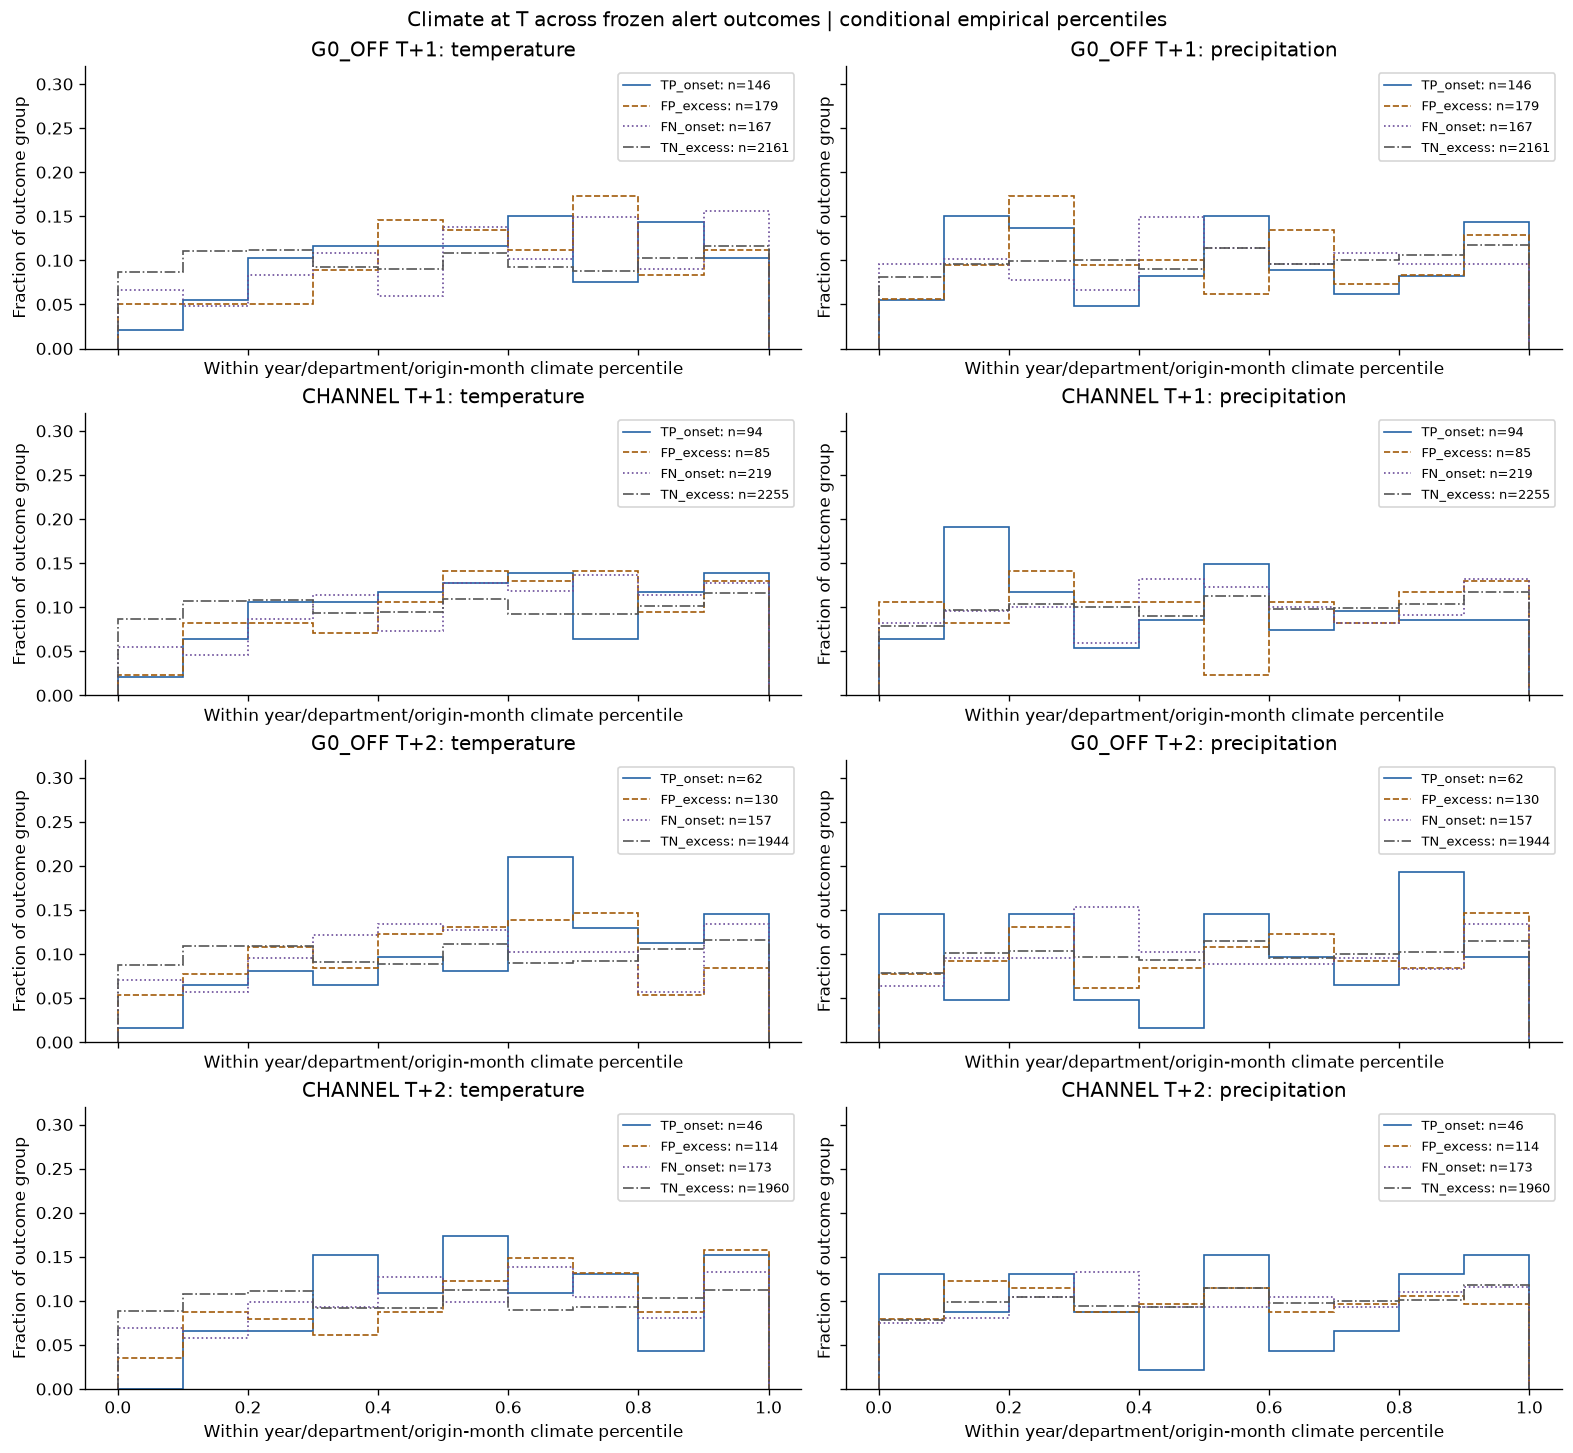

In [16]:
CLIMATE_OUTCOMES = ["TP_onset", "FP_excess", "FN_onset", "TN_excess"]
CLIMATE_OUTCOME_STYLE = {
    "TP_onset": ("#2563a6", "-"),
    "FP_excess": ("#a25b0b", "--"),
    "FN_onset": ("#6b4c9a", ":"),
    "TN_excess": ("#555555", "-."),
}
climate_outcome_frames = []
for climate_arm, climate_alert in [("G0_OFF", "alert"), ("CHANNEL", "channel_alert")]:
    climate_part = climate_current.copy()
    climate_part["arm"] = climate_arm
    climate_part["outcome"] = np.select(
        [
            climate_part[climate_alert] & climate_part.truth.eq(1),
            climate_part[climate_alert] & climate_part.target_excess.eq(0),
            ~climate_part[climate_alert] & climate_part.truth.eq(1),
            ~climate_part[climate_alert] & climate_part.target_excess.eq(0),
            climate_part[climate_alert]
            & climate_part.target_excess.eq(1)
            & climate_part.truth.eq(0),
        ],
        [*CLIMATE_OUTCOMES, "CONTINUATION_ALERT"],
        default="CONTINUATION_NO_ALERT",
    )
    for climate_variable in ["temperature", "precipitation"]:
        climate_part[climate_variable + "_percentile"] = climate_part.groupby(CLIMATE_STRATA)[
            climate_variable
        ].rank(method="average", pct=True)
    climate_outcome_frames.append(climate_part)
climate_outcomes = pd.concat(climate_outcome_frames, ignore_index=True)
climate_tables["outcome_quantiles"] = climate_summary(
    climate_outcomes, ["horizon", "year", "department_code", "arm", "outcome"], list(CLIMATE_FIELDS)
)
climate_tables["outcome_month_quantiles"] = climate_summary(
    climate_outcomes, CLIMATE_STRATA + ["arm", "outcome"], CLIMATE_PRIORITY
)
climate_group_counts = (
    climate_outcomes.groupby(["horizon", "arm", "outcome"]).size().unstack(fill_value=0)
)
assert climate_group_counts.sum(axis=1).to_list() == [2653, 2653, 2422, 2422]
display(climate_group_counts)


def climate_finish(fig, name):
    filename = climate_figures / (name + ".png")
    fig.savefig(filename, bbox_inches="tight")
    display(Image(data=filename.read_bytes()))
    plt.close(fig)


climate_histogram = []
fig, climate_axes = plt.subplots(
    4, 2, figsize=(13, 12), sharex=True, sharey=True, layout="constrained"
)
for climate_i, (climate_h, climate_arm) in enumerate(
    itertools.product([1, 2], ["G0_OFF", "CHANNEL"])
):
    for climate_j, climate_variable in enumerate(["temperature", "precipitation"]):
        climate_ax = climate_axes[climate_i, climate_j]
        climate_panel = climate_outcomes[
            (climate_outcomes.horizon == climate_h) & (climate_outcomes.arm == climate_arm)
        ]
        for climate_outcome, (climate_color, climate_style) in CLIMATE_OUTCOME_STYLE.items():
            climate_values = climate_panel.loc[
                climate_panel.outcome.eq(climate_outcome), climate_variable + "_percentile"
            ].dropna()
            climate_counts, climate_edges = np.histogram(climate_values, bins=np.linspace(0, 1, 11))
            if len(climate_values):
                climate_ax.stairs(
                    climate_counts / len(climate_values),
                    climate_edges,
                    color=climate_color,
                    linestyle=climate_style,
                    label=f"{climate_outcome}: n={len(climate_values)}",
                )
            for climate_bin, climate_count in enumerate(climate_counts):
                climate_histogram.append(
                    dict(
                        horizon=climate_h,
                        arm=climate_arm,
                        variable=climate_variable,
                        outcome=climate_outcome,
                        bin_left=climate_edges[climate_bin],
                        bin_right=climate_edges[climate_bin + 1],
                        count=int(climate_count),
                        observed=len(climate_values),
                    )
                )
        climate_ax.set(
            title=f"{climate_arm} T+{climate_h}: {climate_variable}",
            xlabel="Within year/department/origin-month climate percentile",
            ylabel="Fraction of outcome group",
        )
        climate_ax.legend(fontsize=8)
for climate_ax in climate_axes.flat:
    climate_ax.set_ylim(0, 0.32)
fig.suptitle("Climate at T across frozen alert outcomes | conditional empirical percentiles")
climate_finish(fig, "09_climate_outcome_distributions")
climate_tables["outcome_histogram"] = pd.DataFrame(climate_histogram)

The conditional percentile histograms overlap across detections, false alerts, misses and correct negatives in both arms. G0_OFF T+2 includes 31 continuation alerts in addition to the displayed onset detections and false excess alerts; they remain separately counted. Year/department physical-unit median contrasts are retained in the tables and do not establish incremental prediction.

### 7.3. Predefined calendar lags and onset associations

All four lags and three priority variables are retained in their declared order.
Spearman correlations are calculated separately in each year/horizon/department,
provided at least 20 observed values and three of each onset class are present.
This support screen is a descriptive convention, not a statistical acceptance gate.
No p-values or significant-feature selection are produced.

The table also records a **month-centered rank correlation**: rank climate and
binary onset within origin calendar month, subtract each month's rank means, then
correlate the centered ranks. This explicitly defined descriptive statistic is
not an ordinary Spearman coefficient or a fitted regression. Months with constant
onset contribute no centered outcome variation. Its comparison with raw Spearman
helps expose seasonal composition; it does not prove incremental prediction.

,horizon,variable,lag,cells,supported_cells,raw_positive,raw_negative,centered_positive,centered_negative,raw_min,raw_max,centered_min,centered_max
0,1,precipitation,0,8,8,1,7,4,4,-0.164,0.003,-0.098,0.027
1,1,precipitation,1,8,8,4,4,2,6,-0.075,0.067,-0.088,0.063
2,1,precipitation,2,8,8,5,3,2,6,-0.055,0.139,-0.076,0.050
3,1,precipitation,3,8,8,5,3,4,4,-0.046,0.211,-0.054,0.077
4,1,soil_water,0,8,8,3,5,2,6,-0.132,0.030,-0.049,0.068
...,...,...,...,...,...,...,...,...,...,...,...,...,...
19,2,soil_water,3,8,8,4,4,4,4,-0.120,0.163,-0.076,0.058
20,2,temperature,0,8,8,5,3,6,2,-0.049,0.148,-0.036,0.155
21,2,temperature,1,8,8,4,4,6,2,-0.074,0.136,-0.040,0.145
22,2,temperature,2,8,8,4,4,6,2,-0.053,0.166,-0.043,0.146


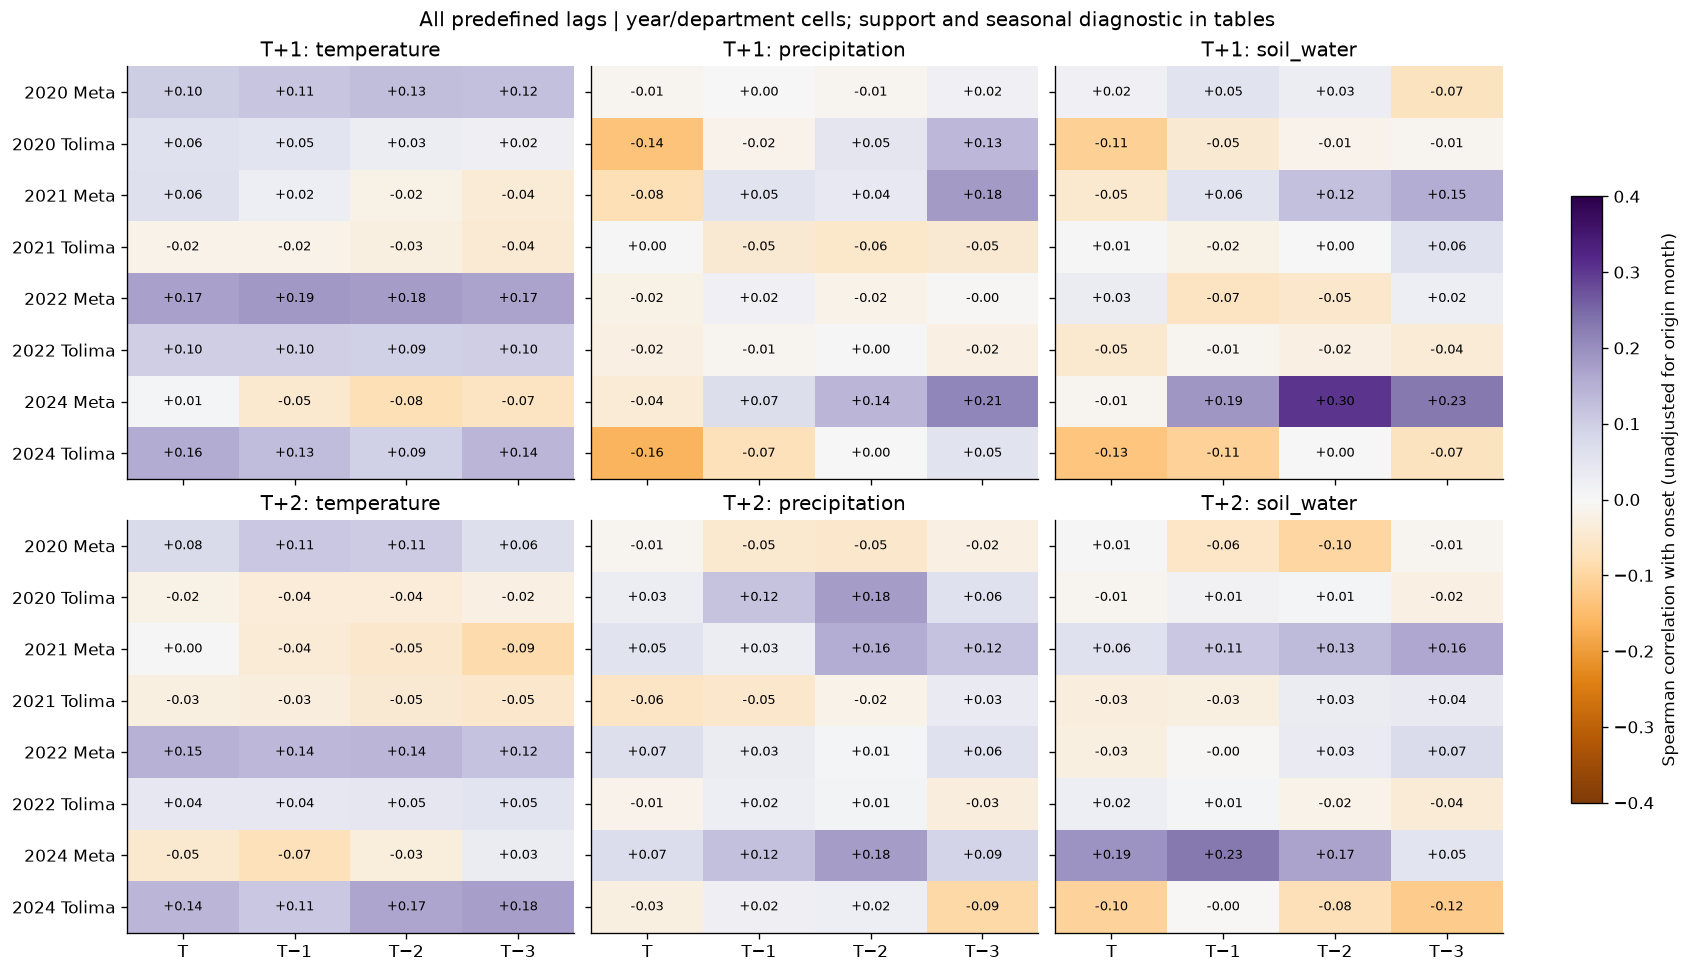

In [17]:
climate_associations = []
for climate_key, climate_block in climate_long.groupby(
    ["horizon", "year", "department_code", "lag"]
):
    for climate_variable in CLIMATE_PRIORITY:
        climate_pair = climate_block[[climate_variable, "truth", "origin_month"]].dropna()
        climate_events = int(climate_pair.truth.sum())
        climate_support = (
            len(climate_pair) >= 20
            and climate_events >= 3
            and len(climate_pair) - climate_events >= 3
        )
        climate_raw = (
            climate_pair[climate_variable].corr(climate_pair.truth, method="spearman")
            if climate_support
            else np.nan
        )
        climate_x = climate_pair.groupby("origin_month")[climate_variable].rank(
            method="average", pct=True
        )
        climate_y = climate_pair.groupby("origin_month").truth.rank(method="average", pct=True)
        climate_x = climate_x - climate_x.groupby(climate_pair.origin_month).transform("mean")
        climate_y = climate_y - climate_y.groupby(climate_pair.origin_month).transform("mean")
        climate_centered = (
            climate_x.corr(climate_y)
            if climate_support and climate_x.std() > 0 and climate_y.std() > 0
            else np.nan
        )
        climate_associations.append(
            {
                **dict(
                    zip(["horizon", "year", "department_code", "lag"], climate_key, strict=True)
                ),
                "variable": climate_variable,
                "rows": len(climate_block),
                "observed": len(climate_pair),
                "onsets": climate_events,
                "supported": climate_support,
                "spearman": climate_raw,
                "month_centered_rank_correlation": climate_centered,
            }
        )
climate_associations = pd.DataFrame(climate_associations)
climate_tables["lag_associations"] = climate_associations
climate_sign_summary = []
for climate_key, climate_block in climate_associations.groupby(["horizon", "variable", "lag"]):
    climate_sign_summary.append(
        {
            **dict(zip(["horizon", "variable", "lag"], climate_key, strict=True)),
            "cells": len(climate_block),
            "supported_cells": int(climate_block.supported.sum()),
            "raw_positive": int(climate_block.spearman.gt(0).sum()),
            "raw_negative": int(climate_block.spearman.lt(0).sum()),
            "centered_positive": int(climate_block.month_centered_rank_correlation.gt(0).sum()),
            "centered_negative": int(climate_block.month_centered_rank_correlation.lt(0).sum()),
            "raw_min": climate_block.spearman.min(),
            "raw_max": climate_block.spearman.max(),
            "centered_min": climate_block.month_centered_rank_correlation.min(),
            "centered_max": climate_block.month_centered_rank_correlation.max(),
        }
    )
climate_sign_summary = pd.DataFrame(climate_sign_summary)
climate_tables["lag_sign_summary"] = climate_sign_summary
display(climate_sign_summary.round(3))

fig, climate_axes = plt.subplots(
    2, 3, figsize=(14, 8), sharex=True, sharey=True, layout="constrained"
)
climate_row_order = pd.MultiIndex.from_product(
    [YEARS, ["50", "73"]], names=["year", "department_code"]
)
for climate_i, climate_h in enumerate([1, 2]):
    for climate_j, climate_variable in enumerate(CLIMATE_PRIORITY):
        climate_ax = climate_axes[climate_i, climate_j]
        climate_panel = climate_associations[
            (climate_associations.horizon == climate_h)
            & (climate_associations.variable == climate_variable)
        ]
        climate_matrix = climate_panel.pivot(
            index=["year", "department_code"], columns="lag", values="spearman"
        ).reindex(climate_row_order)
        climate_image = climate_ax.imshow(
            climate_matrix, vmin=-0.4, vmax=0.4, cmap="PuOr", aspect="auto"
        )
        for climate_r in range(8):
            for climate_c in range(4):
                climate_value = climate_matrix.iloc[climate_r, climate_c]
                climate_ax.text(
                    climate_c,
                    climate_r,
                    f"{climate_value:+.2f}" if pd.notna(climate_value) else "NA",
                    ha="center",
                    va="center",
                    fontsize=8,
                )
        climate_ax.set(
            title=f"T+{climate_h}: {climate_variable}",
            xticks=range(4),
            xticklabels=["T", "T−1", "T−2", "T−3"],
            yticks=range(8),
            yticklabels=[
                f"{year} {'Meta' if dep == '50' else 'Tolima'}" for year, dep in climate_row_order
            ],
        )
fig.colorbar(
    climate_image,
    ax=climate_axes,
    label="Spearman correlation with onset (unadjusted for origin month)",
    shrink=0.7,
)
fig.suptitle(
    "All predefined lags | year/department cells; support and seasonal diagnostic in tables"
)
climate_finish(fig, "10_climate_lag_associations")

Temperature at T has positive raw Spearman association in 7/8 T+1 year/department cells (−0.019 to +0.174), and month-centered rank association in 7/8 (−0.018 to +0.142). At T+2 the corresponding signs are 5/8 and 6/8. No variable/lag has the same association sign across all eight cells. For T+1 precipitation at T, raw signs are negative in 7/8 cells but the month-centered diagnostic splits 4/4. The four temperature lags share weak patterns; no winning lag is selected.

### 7.4. Exclusive G0_OFF alerts near the P75 boundary

Compare onset detections with false excess alerts among G0_OFF alerts absent from
CHANNEL and within one case of target P75. Continuations stay separate. To avoid
letting department/year/season mix manufacture a difference, compare only common
**year × department × origin-month** cells within each horizon, variable and lag.
All original observations remain in the cohort; the common-cell view is explicitly
a subset for this descriptive comparison, never a replacement evaluation cohort.

Within each common cell each group receives total weight `1 / number of common
cells`, distributed equally over its observed records. Thus both groups have
identical cell composition. Coverage, excluded group counts, single-observation
cells and median differences in physical units are retained. Weighted ECDFs are descriptions sensitive to support,
not prediction metrics, classifiers, feature importance or causal estimates.

,horizon,lag,group,original_rows,observed,matched_rows,common_cells,cells_at_least3_each,singleton_group_cells
0,1,0,detected_onset,62,62,46,32,1,21
1,1,0,false_excess,107,107,63,32,1,17
24,2,0,detected_onset,28,28,15,14,0,13
25,2,0,false_excess,74,74,29,14,0,6


quantile                                 0.25     0.50     0.75
horizon variable      group                                    
1       precipitation detected_onset  100.681  152.538  234.394
                      false_excess     91.204  159.691  275.510
        soil_water    detected_onset    0.284    0.384    0.426
                      false_excess      0.323    0.406    0.439
        temperature   detected_onset   20.046   24.074   25.520
                      false_excess     21.792   24.016   25.788
2       precipitation detected_onset  137.154  173.350  359.305
                      false_excess    128.188  219.649  373.297
        soil_water    detected_onset    0.358    0.396    0.438
                      false_excess      0.395    0.438    0.443
        temperature   detected_onset   15.935   23.862   24.854
                      false_excess     13.191   21.201   24.376

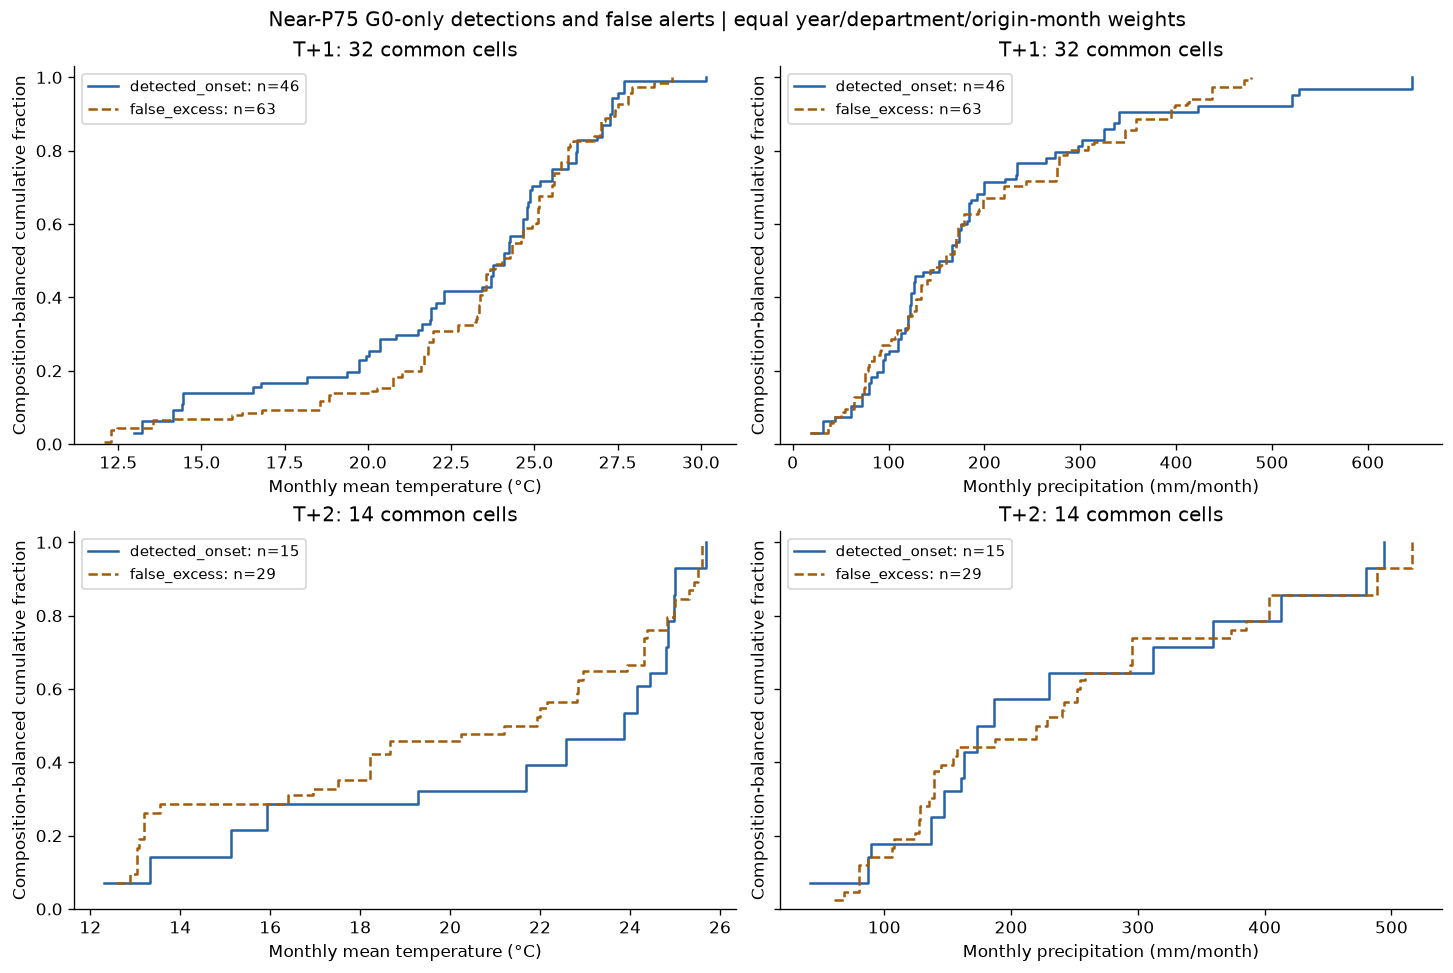

In [18]:
climate_near = climate_long[climate_long.g0_exclusive & climate_long.near_p75].copy()
climate_near["near_group"] = np.select(
    [climate_near.truth.eq(1), climate_near.target_excess.eq(0)],
    ["detected_onset", "false_excess"],
    default="continuation",
)
climate_balance = []
climate_contrasts = []
climate_quantiles = []
climate_near_plot = {}


def climate_weighted_quantile(values, denominators, quantile):
    # Exact inverse CDF: each record has weight 1/(common cells * cell-group n).
    target = Fraction(str(round(float(quantile), 10)))
    cumulative = Fraction(0)
    order = np.argsort(values, kind="stable")
    for index in order:
        cumulative += Fraction(1, int(np.asarray(denominators)[index]))
        if cumulative >= target:
            return np.asarray(values)[index]
    raise ValueError("Weighted empirical distribution did not reach the quantile")


for climate_h, climate_lag, climate_variable in itertools.product(
    [1, 2], CLIMATE_LAGS, CLIMATE_PRIORITY
):
    climate_subset = climate_near[
        (climate_near.horizon == climate_h)
        & (climate_near.lag == climate_lag)
        & climate_near.near_group.ne("continuation")
    ].copy()
    climate_complete = climate_subset.dropna(subset=[climate_variable]).copy()
    climate_sizes = (
        climate_complete.groupby(CLIMATE_STRATA + ["near_group"]).size().unstack(fill_value=0)
    )
    climate_sizes = climate_sizes.reindex(columns=["detected_onset", "false_excess"], fill_value=0)
    climate_common = climate_sizes[
        (climate_sizes.detected_onset > 0) & (climate_sizes.false_excess > 0)
    ]
    climate_membership = pd.MultiIndex.from_frame(climate_complete[CLIMATE_STRATA]).isin(
        climate_common.index
    )
    climate_matched = climate_complete[climate_membership].copy()
    if len(climate_common):
        climate_matched["weight_denominator"] = (
            len(climate_common)
            * climate_matched.groupby(CLIMATE_STRATA + ["near_group"])[climate_variable].transform(
                "size"
            )
        ).astype(int)
        climate_matched["weight"] = 1 / climate_matched.weight_denominator

    for climate_group in ["detected_onset", "false_excess"]:
        climate_original_group = climate_subset[climate_subset.near_group.eq(climate_group)]
        climate_matched_group = climate_matched[climate_matched.near_group.eq(climate_group)]
        climate_balance.append(
            dict(
                horizon=climate_h,
                lag=climate_lag,
                variable=climate_variable,
                group=climate_group,
                original_rows=len(climate_original_group),
                observed=int(climate_original_group[climate_variable].notna().sum()),
                matched_rows=len(climate_matched_group),
                common_cells=len(climate_common),
                cells_at_least3_each=int(
                    (
                        (climate_common.detected_onset >= 3) & (climate_common.false_excess >= 3)
                    ).sum()
                ),
                singleton_group_cells=int(climate_common[climate_group].eq(1).sum()),
            )
        )
        if len(climate_matched_group):
            assert np.isclose(climate_matched_group.weight.sum(), 1)
            for climate_probability in np.linspace(0, 1, 21):
                climate_quantiles.append(
                    dict(
                        horizon=climate_h,
                        lag=climate_lag,
                        variable=climate_variable,
                        group=climate_group,
                        quantile=climate_probability,
                        value=climate_weighted_quantile(
                            climate_matched_group[climate_variable],
                            climate_matched_group.weight_denominator,
                            climate_probability,
                        ),
                        matched_rows=len(climate_matched_group),
                        common_cells=len(climate_common),
                    )
                )
    for climate_key, climate_cell in climate_complete.groupby(CLIMATE_STRATA):
        climate_detected = climate_cell.loc[
            climate_cell.near_group.eq("detected_onset"), climate_variable
        ]
        climate_false = climate_cell.loc[
            climate_cell.near_group.eq("false_excess"), climate_variable
        ]
        climate_contrasts.append(
            {
                **dict(zip(CLIMATE_STRATA, climate_key, strict=True)),
                "lag": climate_lag,
                "variable": climate_variable,
                "detected_n": len(climate_detected),
                "false_n": len(climate_false),
                "detected_median": climate_detected.median(),
                "false_median": climate_false.median(),
                "difference_detected_minus_false": climate_detected.median()
                - climate_false.median(),
                "both_present": bool(len(climate_detected) and len(climate_false)),
            }
        )
    if climate_lag == 0 and climate_variable in ["temperature", "precipitation"]:
        climate_near_plot[(climate_h, climate_variable)] = climate_matched

climate_balance = pd.DataFrame(climate_balance)
climate_quantiles = pd.DataFrame(climate_quantiles)
climate_contrasts = pd.DataFrame(climate_contrasts)
climate_tables.update(
    near_balance=climate_balance,
    near_weighted_quantiles=climate_quantiles,
    near_cell_contrasts=climate_contrasts,
)
display(climate_balance.query("lag == 0").drop(columns="variable").drop_duplicates())
display(
    climate_quantiles[
        climate_quantiles.lag.eq(0) & climate_quantiles["quantile"].isin([0.25, 0.5, 0.75])
    ]
    .pivot(index=["horizon", "variable", "group"], columns="quantile", values="value")
    .round(3)
)

fig, climate_axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained", sharey=True)
for climate_i, climate_h in enumerate([1, 2]):
    for climate_j, climate_variable in enumerate(["temperature", "precipitation"]):
        climate_ax = climate_axes[climate_i, climate_j]
        climate_matched = climate_near_plot[(climate_h, climate_variable)]
        for climate_group, climate_color, climate_style in [
            ("detected_onset", "#2563a6", "-"),
            ("false_excess", "#a25b0b", "--"),
        ]:
            climate_block = climate_matched[
                climate_matched.near_group.eq(climate_group)
            ].sort_values(climate_variable)
            if len(climate_block):
                climate_ax.step(
                    climate_block[climate_variable],
                    climate_block.weight.cumsum(),
                    where="post",
                    color=climate_color,
                    linestyle=climate_style,
                    label=f"{climate_group}: n={len(climate_block)}",
                )
        climate_ncells = climate_balance.query(
            "horizon == @climate_h and lag == 0 and variable == @climate_variable"
        ).common_cells.iloc[0]
        climate_ax.set(
            title=f"T+{climate_h}: {climate_ncells} common cells",
            xlabel=(
                f"{CLIMATE_FIELDS[climate_variable][2]} ({CLIMATE_FIELDS[climate_variable][1]})"
            ),
            ylabel="Composition-balanced cumulative fraction",
            ylim=(0, 1.03),
        )
        climate_ax.legend(fontsize=9)
fig.suptitle(
    "Near-P75 G0-only detections and false alerts | equal year/department/origin-month weights"
)
climate_finish(fig, "11_climate_near_p75")

Composition balancing retains 46/62 near-boundary true detections and 63/107 false alerts in T+1, and 15/28 and 29/74 in T+2. Only 1/32 T+1 common cells and 0/14 T+2 cells have at least three observations in each group. Weighted T+1 temperature medians are 24.074/24.016 °C and precipitation medians 152.54/159.69 mm/month (true/false); T+2 medians are 23.862/21.201 °C and 173.35/219.65 mm/month. Wide overlapping distributions and sparse cells prevent interpreting these differences as a usable error filter.

### Climate coverage and territorial seasonality

The coverage heatmap preserves both horizon populations. Seasonal curves below
use T+1 origins only, so a shared municipality-month is not double-counted across
horizons. Curves are descriptive department/month medians across reused years;
their differing year/municipality composition prevents causal seasonal inference.
All nine variables' year-specific distributions and seasonality remain in the
private derived tables rather than adding redundant figures.

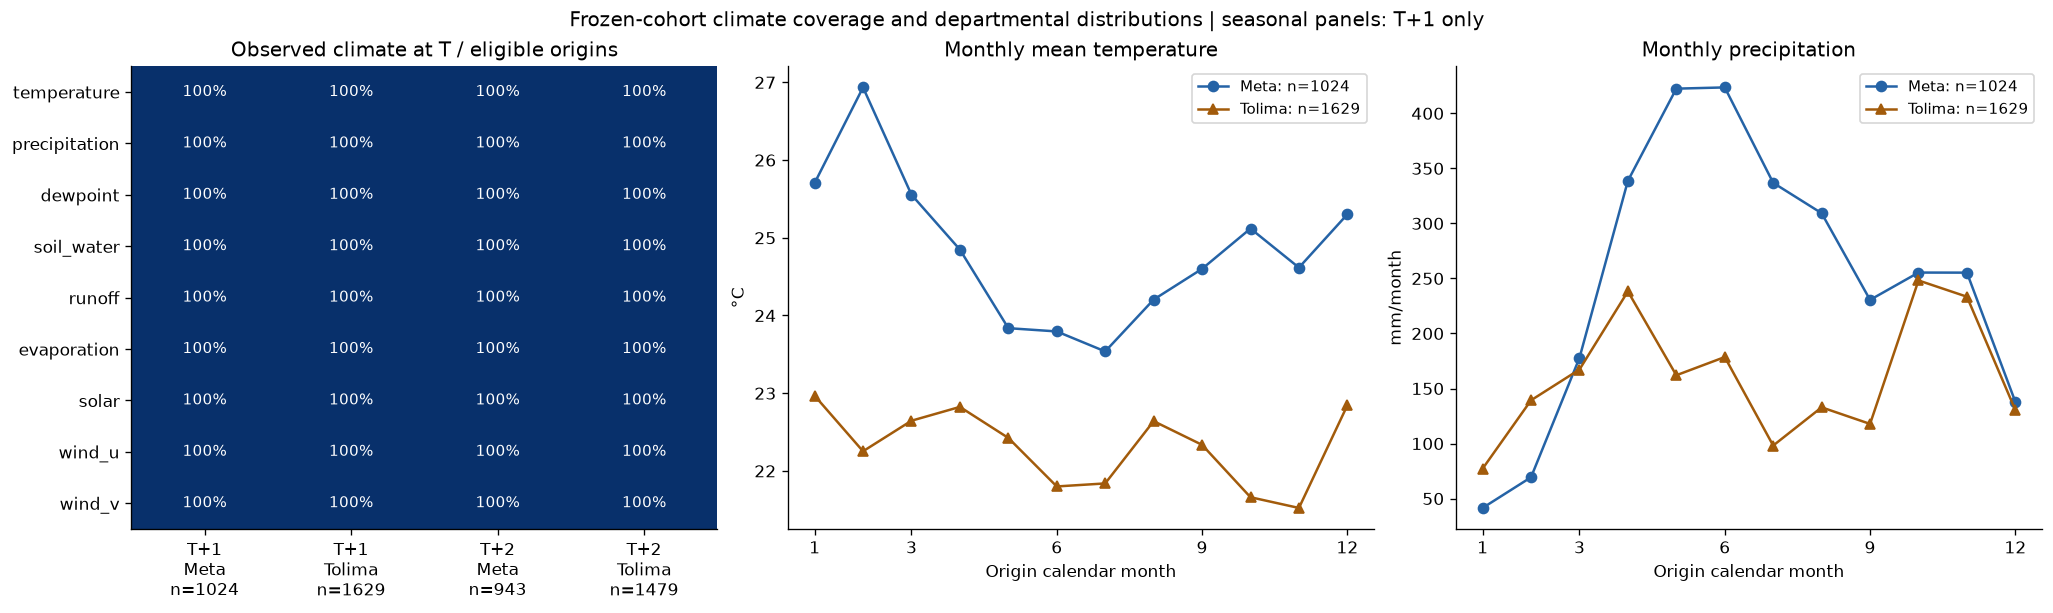

In [19]:
climate_coverage_counts = climate_current.groupby(["horizon", "department_code"]).size()
fig, climate_axes = plt.subplots(1, 3, figsize=(17, 5), layout="constrained")
climate_cov_grid = climate_distribution.pivot(
    index="variable", columns=["horizon", "department_code"], values="coverage"
).reindex(list(CLIMATE_FIELDS))
climate_axes[0].imshow(climate_cov_grid, vmin=0, vmax=1, cmap="Blues", aspect="auto")
for climate_i in range(9):
    for climate_j in range(4):
        climate_h, climate_dep = climate_cov_grid.columns[climate_j]
        climate_row = climate_distribution[
            (climate_distribution.horizon == climate_h)
            & (climate_distribution.department_code == climate_dep)
            & climate_distribution.variable.eq(climate_cov_grid.index[climate_i])
        ].iloc[0]
        climate_axes[0].text(
            climate_j,
            climate_i,
            f"{100 * climate_row.coverage:.0f}%",
            ha="center",
            va="center",
            color="white" if climate_row.coverage > 0.6 else "black",
            fontsize=9,
        )
climate_axes[0].set(
    title="Observed climate at T / eligible origins",
    yticks=range(9),
    yticklabels=list(CLIMATE_FIELDS),
    xticks=range(4),
    xticklabels=[
        f"T+{h}\n{'Meta' if dep == '50' else 'Tolima'}\nn={climate_coverage_counts.loc[(h, dep)]}"
        for h, dep in climate_cov_grid.columns
    ],
)
for climate_ax, climate_variable in zip(
    climate_axes[1:], ["temperature", "precipitation"], strict=True
):
    for climate_dep, climate_label, climate_marker, climate_color in [
        ("50", "Meta", "o", "#2563a6"),
        ("73", "Tolima", "^", "#a25b0b"),
    ]:
        climate_season = (
            climate_current[
                (climate_current.horizon == 1) & (climate_current.department_code == climate_dep)
            ]
            .groupby("origin_month")[climate_variable]
            .agg(["median", "count"])
        )
        climate_ax.plot(
            climate_season.index,
            climate_season["median"],
            color=climate_color,
            marker=climate_marker,
            label=f"{climate_label}: n={int(climate_season['count'].sum())}",
        )
    climate_ax.set(
        title=CLIMATE_FIELDS[climate_variable][2],
        xlabel="Origin calendar month",
        ylabel=CLIMATE_FIELDS[climate_variable][1],
        xticks=[1, 3, 6, 9, 12],
    )
    climate_ax.legend(fontsize=9)
fig.suptitle(
    "Frozen-cohort climate coverage and departmental distributions | seasonal panels: T+1 only"
)
climate_finish(fig, "12_climate_coverage_and_departments")

Scientific disposition: **INSUFFICIENT_EVIDENCE** for justifying additional climatic features as a demonstrated route to separate near-P75 errors. Weak temperature associations justify keeping a narrowly stated question open, but no lag is consistent in all year/department cells and common-cell event support is thin. The evidence does not authorize a climatic DELTA02, a new predictor, or a claim that climate has no possible predictive value. EXP03 already documents conditional climate gains accompanied by false-alert burden and adverse stress results.

### Chapter 7 publication and preservation

Only new aggregate climate derivatives are published under a new content identity.
Original row-level predictions and the canonical dataset are not duplicated.
Source/manifest identities and the exact Chapter 7 source cells bind this extension;
the original publication remains a separate immutable dependency. The README
records execution and original-output preservation checks. Findings and conclusions
are appended separately, leaving F1–F8 and Chapters 1–6 conclusions intact.

In [20]:
for climate_rel, climate_record in climate_sources.items():
    assert identity(ROOT / climate_rel) == climate_record
climate_notebook = json.loads((ROOT / "notebooks/eda_experimental_results.ipynb").read_text())
climate_source_cells = [
    {"cell_type": cell["cell_type"], "source": "".join(cell["source"])}
    for cell in climate_notebook["cells"][CLIMATE_PREFIX_CELLS:]
]
climate_settings = dict(
    schema="eda-exp01-climate-v1",
    original_prefix_cells=CLIMATE_PREFIX_CELLS,
    original_prefix_source_sha256=climate_original_manifest["notebook_source_sha256"],
    lags=CLIMATE_LAGS,
    variables_at_T=list(CLIMATE_FIELDS),
    lagged_variables=CLIMATE_PRIORITY,
    origin_safe_calendar_join=True,
    near_p75_absolute_cases=1,
    imputation=False,
    weighted_quantiles="Exact rational inverse empirical CDF at fixed 0.05 quantile increments",
    spearman_min_rows=20,
    spearman_min_each_onset_class=3,
    seasonal_control="target year/horizon/department/origin month; descriptive only",
    uncertainty="No inferential intervals or significance tests; dependent reused observations",
    feature_selection=False,
    model_fits=0,
    inference_calls=0,
    threshold_searches=0,
    G5="NOT_APPROVED",
    champion="not_selected",
)
climate_payloads = {
    name + ".csv": serialize_table(frame) for name, frame in sorted(climate_tables.items())
}
climate_payloads["settings.json"] = canonical_bytes(climate_settings)
climate_manifest = dict(
    schema="eda-exp01-climate-publication-v1",
    original_publication=CLIMATE_ORIGINAL,
    original_manifest_sha256=CLIMATE_ORIGINAL_SHA,
    sources=climate_sources,
    environment={**environment, "scipy": importlib.metadata.version("scipy")},
    chapter7_source_sha256=bytes_record(canonical_bytes(climate_source_cells))["sha256"],
    files={name: bytes_record(payload) for name, payload in sorted(climate_payloads.items())},
    figures={p.name: identity(p) for p in sorted(climate_figures.glob("*.png"))},
    G5="NOT_APPROVED",
    champion="not_selected",
)
climate_bundle_id = bytes_record(canonical_bytes(climate_manifest))["sha256"]
climate_manifest["bundle_id"] = climate_bundle_id
climate_payloads["manifest.json"] = canonical_bytes(climate_manifest)
climate_publication = publish_bundle(
    ROOT / "data/processed/eda_exp01", climate_bundle_id, climate_payloads
)
print("New climate publication:", climate_publication.relative_to(ROOT))
print("Manifest SHA-256:", bytes_record(climate_payloads["manifest.json"])["sha256"])
print(
    "New climate tables:", len(climate_tables), "| new figures: 4 | original publication preserved"
)

New climate publication: data/processed/eda_exp01/75a1b9e36a4d1792f3dbec72e0ac9013f0918f5115c66deb19832e26c977d2ce
Manifest SHA-256: 5b15e3ef3904383e2774606ac56b8472f6d45b51eb0d6cf16503520b9bd86e20
New climate tables: 12 | new figures: 4 | original publication preserved
